# NYC Yellow Taxi 2015–2016 — Anomaly Detection with Statistical Methods

In Task 2 I cleaned the data and built a trip-level feature matrix. In this notebook I searched for anomalies on the same matrix, without building a model, using statistical methods only. The goal has two sides: finding which records and which time periods are unusual, and setting a baseline for the ML methods that come next. An ML method adds value only if it catches what these simple methods miss.

Findings carried over from the previous two notebooks that shape this work directly:
- Task 2 deleted as few rows as possible. Most problematic records are still in the matrix and are marked with quality flags. These flags are the first reference I compare the statistical methods against.
- Numeric distributions are right-skewed. Task 1 showed that IQR and MAD give meaningful bounds on this data only on a log scale.
- Most of the top 1% are airport trips. A bound on a single variable cannot tell an anomalous trip from a long, expensive one.
- Most error types are concentrated in one vendor's records (Task 2, 13.2).
- Durations are not reliable on the nights the clocks change (Task 2, 13.2).

## 1. Contents: questions and where they are answered

| Topic | Section |
|---|---|
| 1. Anomaly definition and business perspective: what I count as an anomaly, what I expect | 3 |
| 2. Variable-based methods: univariate and multivariate; is a record that is anomalous in one variable still anomalous in a multivariate context | 5, 6, 7 |
| 3. Time-based anomaly detection: spikes, unexpected drops, points that do not fit the seasonal pattern | 8 |
| 4. Comparing the methods: do they catch the same records or different anomalies | 9 |
| 5. Manual inspection of anomaly examples | 10 |
| 6. Business perspective: which processes anomalies help, how far statistics goes | 11 |
| Findings and next steps: which method worked in which situation, what I expect from ML methods | 12 |

### My checklist

What I set out to do:

- [x] Write down the anomaly definition and my expectations before writing code (3)
- [x] Apply univariate and multivariate methods and compare them (5, 6, 7)
- [x] Build a time method that accounts for normal behaviour changing over time (8)
- [x] Show whether the methods flag the same records or different ones (9)
- [x] Inspect the records each method flags (10)
- [x] Highlight anomaly points in red in the charts (5, 8, 9)

Items I added:

- [x] Measure whether the statistical methods find trips that Task 2's flags already catch or new trips (4, 9)
- [x] A parameter sensitivity table before each threshold decision (5, 8)
- [x] Fit thresholds on the fit window, apply them to the holdout and check whether the flagged share changes between the two periods (5, 6, 7)
- [x] Show, for each method, the number of flags expected with no anomaly present and the daily alarm budget (5, 7, 9)
- [x] Segment-based robust covariance in the multivariate method; masking comparison with the classical covariance (7)
- [x] Flag rates by vendor and day for collective anomalies that are not visible in single records (8)
- [x] Compare the real-time and retrospective time methods (8, 9)
- [x] Write the label scheme and the external event list before seeing results (3)
- [x] Use a known data error as a test case: trips whose duration is one hour too long on the spring-forward night (7.3)

## 2. Setup

In the setup cells I loaded the libraries, defined the folders and opened the DuckDB connection. I read the location of the matrix, Task 2's rules and the end of the fit window from the `feature_list.json` file Task 2 saved. I did not type the path or the thresholds by hand, so this notebook stays tied exactly to the matrix Task 2 produced. All anomaly-detection code is written inside the section that uses it.

I kept the thresholds set in this notebook in the `RULES` dictionary and those coming from Task 2 separately in `TASK2_RULES`. Each threshold is added right after the evidence that justifies it. Points flagged as anomalies have the same red colour in every chart.

In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
TRIP_FILES = str(RAW_DIR / "yellow_tripdata_*.parquet")
ZONE_LOOKUP = str(RAW_DIR / "taxi_zone_lookup.csv")
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "task2"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures" / "task3"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_LIST = json.loads((ARTIFACT_DIR / "feature_list.json").read_text())
MATRIX_GLOB = (PROJECT_ROOT / FEATURE_LIST["matrix"]["path"] / "**" / "*.parquet").as_posix()
TASK2_RULES = FEATURE_LIST["rules"]
FIT_END = TASK2_RULES["fit_end"]

RANDOM_SEED = 42
RULES = {}
ANOMALY_COLOR = "#c0392b"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

I defined the matrix as `matrix` and the raw data as `raw_trips`, two lazy views. Neither loads the data into memory; every query reads from the files. I used the raw data in only two places: counting the rows deleted in Task 2 (4) and looking at a record's raw fields during manual inspection (10).

I compared the matrix row count with the count Task 2 recorded. If the two differ the cell raises an error and the notebook stops, so I never work on a wrong or incomplete matrix.

In [2]:
con = duckdb.connect()
con.execute("SET memory_limit = '6GB'")
con.execute("SET threads = 4")
con.execute("SET enable_progress_bar = false")

con.execute(f"CREATE OR REPLACE VIEW matrix AS SELECT * FROM read_parquet('{MATRIX_GLOB}', hive_partitioning = true)")
con.execute(f"CREATE OR REPLACE VIEW raw_trips AS SELECT * FROM read_parquet('{TRIP_FILES}')")

matrix_rows = con.execute("SELECT COUNT(*) FROM matrix").fetchone()[0]
raw_rows = con.execute("SELECT COUNT(*) FROM raw_trips").fetchone()[0]
assert matrix_rows == FEATURE_LIST["matrix"]["rows"], "The matrix differs from the one Task 2 recorded"

pd.Series({
    "DuckDB / pandas": f"{duckdb.__version__} / {pd.__version__}",
    "raw trips": f"{raw_rows:,}",
    "matrix rows": f"{matrix_rows:,}",
    "matrix rows recorded by Task 2": f"{FEATURE_LIST['matrix']['rows']:,}",
    "rows deleted in Task 2": f"{raw_rows - matrix_rows:,}",
    "fit window ends": FIT_END,
}, name="value").to_frame()

,value
DuckDB / pandas,1.5.5 / 3.0.5
raw trips,"277,171,036"
matrix rows,"277,062,314"
matrix rows recorded by Task 2,"277,062,314"
rows deleted in Task 2,"108,722"
fit window ends,2016-07-01


## 3. Anomaly definition

Before writing code I wrote down what I would count as an anomaly in this data and what I expected from the methods. I compared the results with these expectations.

### 3.1 Why a trip can be anomalous

For a taxi platform, an anomaly is anything outside normal operation that calls for some action. I split this into three statistical types:
- Point anomaly: a record that is unusual on its own. Example: a trip of millions of miles.
- Contextual anomaly: a value that is normal on its own but unusual in its context. Example: a speed that is normal at 03:00 is unusual in Midtown at 18:00.
- Collective anomaly: single records look normal, but together they form an unusual pattern. Example: the same kind of error multiplying in one vendor's records from a certain day on.

From a business point of view I looked for five kinds of anomaly:

| Kind | What it means | Which columns show it | Where it helps on the platform |
|---|---|---|---|
| Data and system error | The record does not describe the real trip correctly | quality flags, distance, duration, `VendorID` | data quality monitoring |
| Fare anomaly | The fare cannot be explained by distance and duration | `fare_excess`, `route_ratio`, surcharges | fare audit |
| Duration and speed anomaly | The trip is too slow or too fast for its place and hour | `speed_ratio`, `duration_min` | operations, arrival-time estimates |
| Spatial anomaly | A rarely seen pickup–dropoff pair or an unknown zone | `od_pair_trips`, zone flags | route audit |
| Time anomaly | The number of trips or the error rate in an hour is very different from expected | hourly and daily counts | demand alarm, system monitoring |

### 3.2 My expectations

Based on the previous two notebooks I expected:
- Most records flagged by univariate methods will either already carry Task 2's flags or be legitimate but rare trips, such as airport trips.
- Multivariate methods will count trips that look extreme in one column but are consistent with the others as normal. A long, expensive airport trip is an example. They will separate records whose columns contradict each other, such as a very long distance with a very short duration.
- Time methods will find the events I know from the outside world (3.3). If they do not, something is wrong with the method.
- Since error types depend on the vendor, some anomalies will show up not in single records but in rates by vendor and day.

### 3.3 External event list written before seeing results

To evaluate the time methods I listed events I know from the outside world, not from the data. I wrote the list before seeing the results. Looking for events to explain a deviation found afterwards would make the method look better than it is.

| Event | Date | Source | Expected effect |
|---|---|---|---|
| Blizzard and travel ban in New York | 23–24 January 2016 | [NYC snow report](https://a860-gpp.nyc.gov/downloads/v692t6235?locale=en) | very sharp drop in trips |
| Spring-forward nights | 2015-03-08, 2016-03-13 | Task 2, 6.1 | almost no trips in the 02:00 hour |
| Fall-back nights | 2015-11-01, 2016-11-06 | Task 2, 6.1 | the 01:00 hour is counted twice |
| Federal holidays and general election days | 22 days | Task 2, 5.4 | deviation from the workday pattern |

### 3.4 Label scheme for manual inspection

Since there is no ground truth, I classified the flagged records with these labels, defined before looking at any record (Section 10):

| Label | Definition | Example |
|---|---|---|
| Real error | The record describes a trip that is physically impossible or contradicts itself | 30 miles in half a minute |
| Legitimate but rare | The trip is unusual but consistent and possible | a two-hour trip from JFK to Manhattan in heavy traffic |
| Explained anomaly | Truly unusual, but caused by an event in the 3.3 list | demand dropping on the blizzard night |
| Unclear | The record does not hold enough information to decide | a trip with a reasonable fare but no recorded distance |

I measured a method's success by the share of real errors and explained anomalies among the records it flags. I counted legitimate but rare records as false alarms.

## 4. Trips flagged by rules

### 4.1 What Task 2's flags catch

Before moving to statistical methods I measured how many trips Task 2's rule-based flags already mark. In later sections I compared the statistical methods with this number: if a trip a method flags is already flagged, the method has found nothing new.

I computed each flag's share in the fit window and the holdout. I counted flags that were not evaluated (NULL) as unflagged, so all rates are over all trips. `is_route_ratio_undefined` does not mark an error; it marks trips whose route ratio cannot be computed (same zone, short centroid distance, unknown zone). That is why I left it out of the "at least one flag" total.

In [3]:
QUALITY_FLAGS = [
    "is_distance_missing", "is_distance_invalid", "is_duration_invalid", "is_very_short",
    "is_high_speed", "is_amount_mismatch", "is_fare_below_minimum", "is_ratecode_invalid",
    "is_extra_mismatch", "is_tip_rate_extreme", "is_route_ratio_undefined",
]
DEFINITIONAL_FLAGS = ["is_route_ratio_undefined"]
RULE_FLAGS = [flag for flag in QUALITY_FLAGS if flag not in DEFINITIONAL_FLAGS]

flag_rate = ",\n        ".join(
    f"100.0 * AVG(CAST(COALESCE({flag}, false) AS INTEGER)) AS {flag}" for flag in QUALITY_FLAGS)
any_rule_flag = " OR ".join(f"COALESCE({flag}, false)" for flag in RULE_FLAGS)
rule_flag_count = " + ".join(f"CAST(COALESCE({flag}, false) AS INTEGER)" for flag in RULE_FLAGS)

flag_rates = con.execute(f"""
    SELECT
        CASE WHEN in_fit_window THEN 'fit' ELSE 'holdout' END        AS period,
        COUNT(*)                                                     AS trips,
        {flag_rate},
        100.0 * AVG(CAST(({any_rule_flag}) AS INTEGER))              AS any_rule_flag,
        100.0 * AVG(CAST(({rule_flag_count}) >= 2 AS INTEGER))       AS two_or_more_rule_flags
    FROM matrix
    GROUP BY 1
    ORDER BY 1
""").df().set_index("period").T

flag_rates.apply(
    lambda row: row.map("{:,.0f}".format) if row.name == "trips" else row.map("{:.3f}".format),
    axis=1,
)

period,fit,holdout
trips,"215,335,294","61,727,020"
is_distance_missing,0.584,0.597
is_distance_invalid,0.082,0.095
is_duration_invalid,0.237,0.268
is_very_short,0.673,0.710
is_high_speed,0.024,0.025
is_amount_mismatch,0.331,0.211
is_fare_below_minimum,0.041,0.046
is_ratecode_invalid,0.007,0.002
is_extra_mismatch,0.379,0.348


The share of trips caught by at least one of Task 2's rules is 1.806% in the fit window and 1.738% in the holdout. The share caught by two or more rules is also almost the same in both periods (0.580% and 0.597%). The rules flag a small part of the trips, and that part does not grow or shrink over time. I left `is_route_ratio_undefined` out of this total. It does not mark an error and on its own flags about 37% of trips. Had it been included, the share of flagged trips would look about twenty times larger.

Most flags have similar rates in both periods; one behaves differently: `is_amount_mismatch` is 0.331% in the fit window and 0.211% in the holdout. That is a drop of more than a third. The averages of the two periods do not tell whether the drop is gradual or comes from events on specific days. I looked into it by day and vendor in Section 8.

I used these rates as a reference in later sections. If a statistical method flags far more than 1.8% of trips, most of what it flags are trips the rules do not catch. I separated whether these are errors or legitimate but rare trips in Sections 9 and 10.

### 4.2 Where Task 2's thresholds come from

If the bound a statistical method finds lands where one of Task 2's thresholds is, the method has not found anything new; it has repeated Task 2's decision. To tell these apart I looked at where the thresholds used in the flags come from. A threshold either comes from the tariff (initial charge, surcharge hours) or is a plausibility limit set with domain knowledge (such as 100 miles or 80 mph). If a threshold had been computed from a percentile of the data, the statistical methods would be expected to rediscover it and that would not count as a finding.

In [4]:
THRESHOLD_SOURCES = {
    "max_total_amount": ("domain limit, rows above are deleted", "money columns"),
    "max_distance_miles": ("domain limit", "is_distance_invalid"),
    "max_speed_mph": ("domain limit", "is_distance_invalid"),
    "max_duration_s": ("domain limit", "is_duration_invalid"),
    "high_speed_mph": ("domain limit", "is_high_speed"),
    "very_short_s": ("domain limit", "is_very_short"),
    "tip_rate_cap": ("domain limit", "is_tip_rate_extreme"),
    "min_fare": ("tariff", "is_fare_below_minimum"),
    "overnight_start": ("tariff", "is_extra_mismatch"),
    "overnight_end": ("tariff", "is_extra_mismatch"),
    "peak_start": ("tariff", "is_extra_mismatch"),
    "peak_end": ("tariff", "is_extra_mismatch"),
    "overnight_extra": ("tariff", "is_extra_mismatch"),
    "peak_extra": ("tariff", "is_extra_mismatch"),
    "boundary_hours": ("tariff, ambiguous edges", "is_extra_mismatch"),
    "meter_holiday_max_peak_pct": ("decision rule", "tariff calendar"),
}

pd.DataFrame(
    [(rule, TASK2_RULES[rule], source, used_by) for rule, (source, used_by) in THRESHOLD_SOURCES.items()],
    columns=["rule", "value", "source", "used_by"],
).set_index("rule")

,value,source,used_by
rule,,,
max_total_amount,500,"domain limit, rows above are deleted",money columns
max_distance_miles,100,domain limit,is_distance_invalid
max_speed_mph,80,domain limit,is_distance_invalid
max_duration_s,14400,domain limit,is_duration_invalid
high_speed_mph,50,domain limit,is_high_speed
very_short_s,60,domain limit,is_very_short
tip_rate_cap,1.0,domain limit,is_tip_rate_extreme
min_fare,2.5,tariff,is_fare_below_minimum
overnight_start,20,tariff,is_extra_mismatch


None of the thresholds in the table is computed from the data, that is, from a percentile. Seven are round limits set with domain knowledge (such as 500 dollars, 100 miles, 80 mph, 4 hours), eight come from the tariff, and one is a decision rule written in Task 2 to add election day to the tariff calendar. This matters, because the statistical methods in later sections compute their bounds from the data. If a statistical method also flags the trips these flags mark, two different methods have independently found the same trips suspicious. The method has not copied Task 2's threshold. I measured this overlap in Section 9.

The first row of the table also shows a limitation. Task 2 deleted rows whose total amount exceeds 500 dollars or whose money values are invalid. The difference between the raw data and the matrix is 108,722 rows (the table in Section 2). The statistical methods cannot see these rows, so I could study the tail of the fare distribution only below 500 dollars.

## 5. Univariate methods

### 5.1 Continuous variables

First I gave each trip an anomaly score by looking at its columns one at a time. I picked four continuous variables: distance, duration, speed ratio (`speed_ratio`) and fare excess (`fare_excess`). The first two are the trip's raw measurements. The last two are values Task 2 normalised by context: the speed ratio compares the trip's speed with the speed expected for that zone and hour, and the fare excess compares the fare with the fare the distance requires.

Task 1 showed that on the skewed distributions in this data IQR and MAD give meaningful bounds only on a log scale. So I studied distance, duration and speed ratio on a log scale. Fare excess can be negative, so its logarithm cannot be taken; I left it on the raw scale. A trip can be anomalous for being too short or too long, too slow or too fast, so I looked at both tails.

I gave each trip two scores. The IQR score measures how far outside the first or third quartile the trip is, in IQR units. The MAD score measures the distance from the median in robust standard deviations; the robust standard deviation is 1.4826 × MAD. I computed the quartiles, the median and the MAD from the fit window only.

I did not pick the bound by hand. My rule was: the bound is the score that flags exactly 1% of trips in the fit window. I chose 1% for two reasons: it is the same level as the p99 cut in Task 1, and it lets me compare the two methods while they flag the same number of trips. To see whether the result depends on this level, I repeated the computation at 0.5% and 2%.

I also decided which method to use with a rule written in advance: at the same level, the method with the lower share of airport trips among the trips it flags. As seen in Task 1, airport trips are long and expensive but legitimate. A method that flags them finds a rare kind of trip, not an anomaly. If the difference between the two methods was below 2 points I would pick MAD, because the MAD score uses the same scale on both sides of the median.

In [5]:
UNIVARIATE_COLUMNS = {
    "trip_distance": ("ln(trip_distance)", "trip_distance > 0"),
    "duration_min": ("ln(duration_min)", "duration_min > 0"),
    "speed_ratio": ("ln(speed_ratio)", "speed_ratio > 0"),
    "fare_excess": ("fare_excess", "fare_excess IS NOT NULL"),
}
FLAG_LEVELS_PCT = [0.5, 1.0, 2.0]


def sql_number(value):
    """Exact text form of a float for an SQL literal."""
    return f"{float(value):.17g}"


def fit_statistics(source):
    """Exact quartiles, median and MAD of v in the fit window."""
    q1, median, q3 = con.execute(
        f"SELECT quantile_cont(v, [0.25, 0.5, 0.75]) FROM ({source}) WHERE in_fit_window").fetchone()[0]
    mad = con.execute(
        f"SELECT quantile_cont(abs(v - {sql_number(median)}), 0.5) FROM ({source}) WHERE in_fit_window").fetchone()[0]
    return q1, median, q3, mad


def scored_trips(source, q1, median, q3, mad):
    """Adds the IQR and MAD scores and their lower-tail markers to every trip."""
    iqr, robust_sd = q3 - q1, 1.4826 * mad
    return f"""
        SELECT *,
            GREATEST(({sql_number(q1)} - v) / {sql_number(iqr)}, (v - {sql_number(q3)}) / {sql_number(iqr)}) AS iqr_score,
            abs(v - {sql_number(median)}) / {sql_number(robust_sd)} AS mad_score,
            v < {sql_number(q1)} AS iqr_lower,
            v < {sql_number(median)} AS mad_lower
        FROM ({source})"""


def flag_shares(method, k):
    """Aggregates for one threshold: flagged share in fit and holdout, and the make-up of the flagged fit trips."""
    flagged = f"{method}_score > {sql_number(k)}"
    fit_flagged = f"in_fit_window AND {flagged}"
    return [
        f"100.0 * AVG(CAST({flagged} AS INTEGER)) FILTER (WHERE in_fit_window)",
        f"100.0 * AVG(CAST({flagged} AS INTEGER)) FILTER (WHERE NOT in_fit_window)",
        f"100.0 * AVG(CAST(airport AS INTEGER)) FILTER (WHERE {fit_flagged})",
        f"100.0 * AVG(CAST(rule_flagged AS INTEGER)) FILTER (WHERE {fit_flagged})",
        f"100.0 * AVG(CAST({method}_lower AS INTEGER)) FILTER (WHERE {fit_flagged})",
    ]

In [6]:
SHARE_COLUMNS = ["fit_pct", "holdout_pct", "airport_pct_flagged", "rule_flagged_pct", "lower_tail_pct"]
quantiles = [1 - level / 100 for level in FLAG_LEVELS_PCT]

univariate_stats = {}
comparison_rows = []
for column, (expression, condition) in UNIVARIATE_COLUMNS.items():
    source = (f"SELECT {expression} AS v, in_fit_window, ({any_rule_flag}) AS rule_flagged, "
              f"trip_segment IN ('jfk', 'lga', 'ewr') AS airport FROM matrix WHERE {condition}")
    univariate_stats[column] = fit_statistics(source)
    scored = scored_trips(source, *univariate_stats[column])

    iqr_k, mad_k = con.execute(f"SELECT quantile_cont(iqr_score, {quantiles}), quantile_cont(mad_score, {quantiles}) "
                               f"FROM ({scored}) WHERE in_fit_window").fetchone()
    thresholds = [(method, level, k) for method, ks in [("iqr", iqr_k), ("mad", mad_k)]
                  for level, k in zip(FLAG_LEVELS_PCT, ks)]

    aggregates = ["100.0 * AVG(CAST(airport AS INTEGER)) FILTER (WHERE in_fit_window)"]
    aggregates += [sql for method, _, k in thresholds for sql in flag_shares(method, k)]
    result = con.execute(f"SELECT {', '.join(aggregates)} FROM ({scored})").fetchone()

    for i, (method, level, k) in enumerate(thresholds):
        shares = dict(zip(SHARE_COLUMNS, result[1 + 5 * i: 6 + 5 * i]))
        comparison_rows.append({"column": column, "level_pct": level, "method": method.upper(), "k": k,
                                "airport_pct_all": result[0], **shares})

univariate_comparison = pd.DataFrame(comparison_rows).set_index(["column", "level_pct", "method"])
univariate_comparison.round(3)

k  airport_pct_all  fit_pct  holdout_pct  \
column        level_pct method                                                 
trip_distance 0.5       IQR     1.664            6.613    0.496        0.587   
              1.0       IQR     1.563            6.613    0.985        1.127   
              2.0       IQR     1.475            6.613    1.997        2.201   
              0.5       MAD     3.095            6.613    0.497        0.588   
              1.0       MAD     2.955            6.613    0.998        1.141   
              2.0       MAD     2.833            6.613    1.983        2.186   
duration_min  0.5       IQR     2.338            6.639    0.494        0.525   
              1.0       IQR     1.628            6.639    1.000        1.073   
              2.0       IQR     1.322            6.639    1.979        2.206   
              0.5       MAD     3.858            6.639    0.493        0.525   
              1.0       MAD     2.897            6.639    0.989        1.056   
              2.0       MAD     2.468            6.639    2.000        2.211   
speed_ratio   0.5       IQR     2.391            6.697    0.500        0.596   
              1.0       IQR     2.044            6.697    1.000        1.161   
              2.0       IQR     1.706            6.697    2.000        2.288   
              0.5       MAD     3.900            6.697    0.500        0.598   
              1.0       MAD     3.431            6.697    1.000        1.165   
              2.0       MAD     2.975            6.697    2.000        2.294   
fare_excess   0.5       IQR     3.998            4.579    0.500        0.807   
              1.0       IQR     3.210            4.579    0.998        1.549   
              2.0       IQR     2.467            4.579    2.000        2.952   
              0.5       MAD     6.885            4.579    0.500        0.808   
              1.0       MAD     5.708            4.579    1.000        1.553   
              2.0       MAD     4.600            4.579    1.999        2.953   

                                airport_pct_flagged  rule_flagged_pct  \
column        level_pct method                                          
trip_distance 0.5       IQR                  38.472            28.073   
              1.0       IQR                  63.616            15.143   
              2.0       IQR                  78.093             8.192   
              0.5       MAD                  40.349            27.503   
              1.0       MAD                  65.008            14.722   
              2.0       MAD                  79.154             8.000   
duration_min  0.5       IQR                  14.101            99.627   
              1.0       IQR                  13.101            70.804   
              2.0       IQR                  21.656            37.311   
              0.5       MAD                  14.087            99.674   
              1.0       MAD                  12.359            71.551   
              2.0       MAD                  20.118            36.994   
speed_ratio   0.5       IQR                  26.871             7.248   
              1.0       IQR                  31.348             4.971   
              2.0       IQR                  30.379             3.568   
              0.5       MAD                  26.487             7.250   
              1.0       MAD                  31.007             4.969   
              2.0       MAD                  30.127             3.566   
fare_excess   0.5       IQR                  19.536             1.197   
              1.0       IQR                  16.299             0.956   
              2.0       IQR                  13.398             0.829   
              0.5       MAD                  19.516             1.177   
              1.0       MAD                  16.261             0.938   
              2.0       MAD                  13.374             0.810   

                                lower_tail_pct  
column 

In [7]:
airport_by_method = univariate_comparison["airport_pct_flagged"].unstack("method")
airport_by_method["difference"] = airport_by_method["IQR"] - airport_by_method["MAD"]
airport_by_method["choice"] = np.where(
    airport_by_method["difference"].abs() < 2, "MAD",
    np.where(airport_by_method["IQR"] < airport_by_method["MAD"], "IQR", "MAD"))
assert set(airport_by_method["choice"]) == {"MAD"}, "The rule did not pick MAD everywhere"

RULES["univariate_flag_level_pct"] = 1.0
RULES["univariate_mad_k"] = (univariate_comparison
                             .xs((1.0, "MAD"), level=("level_pct", "method"))["k"]
                             .to_dict())

airport_by_method.round(3)

method                      IQR     MAD  difference choice
column        level_pct                                   
duration_min  0.5        14.101  14.087       0.014    MAD
              1.0        13.101  12.359       0.742    MAD
              2.0        21.656  20.118       1.539    MAD
fare_excess   0.5        19.536  19.516       0.020    MAD
              1.0        16.299  16.261       0.038    MAD
              2.0        13.398  13.374       0.023    MAD
speed_ratio   0.5        26.871  26.487       0.384    MAD
              1.0        31.348  31.007       0.341    MAD
              2.0        30.379  30.127       0.251    MAD
trip_distance 0.5        38.472  40.349      -1.877    MAD
              1.0        63.616  65.008      -1.393    MAD
              2.0        78.093  79.154      -1.061    MAD

In [8]:
from scipy.stats import norm

fit_days = (pd.Timestamp(FIT_END) - pd.Timestamp("2015-01-01")).days
fit_trips_per_day = flag_rates.loc["trips", "fit"] / fit_days

alarm_view = (univariate_comparison
              .xs((1.0, "MAD"), level=("level_pct", "method"))[["k", "fit_pct", "holdout_pct"]]
              .copy())
alarm_view["normal_expected_pct"] = 200 * norm.sf(alarm_view["k"])
alarm_view["observed_to_normal"] = alarm_view["fit_pct"] / alarm_view["normal_expected_pct"]
alarm_view["alarms_per_day_fit"] = alarm_view["fit_pct"] / 100 * fit_trips_per_day

alarm_view.round(3)

,k,fit_pct,holdout_pct,normal_expected_pct,observed_to_normal,alarms_per_day_fit
column,,,,,,
trip_distance,2.955,0.998,1.141,0.313,3.192,3930.708
duration_min,2.897,0.989,1.056,0.377,2.623,3894.645
speed_ratio,3.431,1.000,1.165,0.060,16.633,3936.659
fare_excess,5.708,1.000,1.553,0.000,872998.223,3936.119


The most striking column of the table is the ratio of the observed share to the share expected under a normal distribution. If the data were normal, the bound chosen for distance would flag 0.313% of trips; in reality it flags 0.998%, that is 3.192 times more. This ratio is 16.633 for the speed ratio and 872,998 for fare excess. For fare excess, the number of trips that would be flagged under the normal assumption is almost zero. A method based on the normal distribution, such as the classic "3 sigma" rule, would barely see the tails in this data. That is why I computed the bound from the data's own percentile and not from the normal assumption.

The last column shows the operational side. The 1% level means about 3,900 trips a day in the fit window for each variable. If the four variables are used together, the daily count can go up to four times that, depending on how much the flagged trips overlap. Reviewing that many alarms every day is not realistic for an audit team. So univariate bounds cannot be an alarm system on their own; they can be used to rank the scores and give priority to the most extreme trips. I measured how many trips the statistical flags mark together in Section 9.

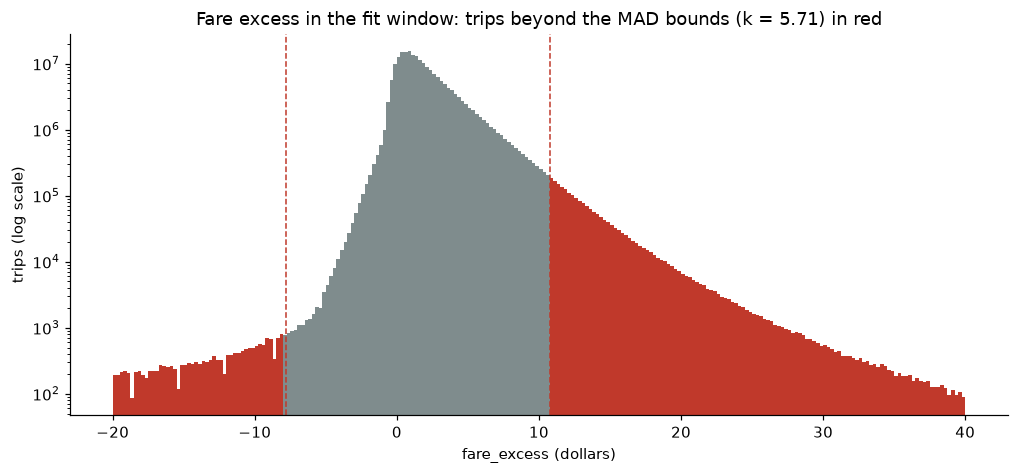

In [9]:
q1, median, q3, mad = univariate_stats["fare_excess"]
k = RULES["univariate_mad_k"]["fare_excess"]
lower, upper = median - k * 1.4826 * mad, median + k * 1.4826 * mad
BIN_WIDTH = 0.25

fare_histogram = con.execute(f"""
    SELECT FLOOR(fare_excess / {BIN_WIDTH}) * {BIN_WIDTH} AS bin_start, COUNT(*) AS trips
    FROM matrix
    WHERE in_fit_window AND fare_excess BETWEEN -20 AND 40
    GROUP BY 1 ORDER BY 1
""").df()
outside = (fare_histogram["bin_start"] >= upper) | (fare_histogram["bin_start"] + BIN_WIDTH <= lower)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(fare_histogram["bin_start"], fare_histogram["trips"], width=BIN_WIDTH, align="edge",
       color=np.where(outside, ANOMALY_COLOR, "#7f8c8d"))
for bound in (lower, upper):
    ax.axvline(bound, color=ANOMALY_COLOR, linestyle="--", linewidth=1)
ax.set_yscale("log")
ax.set_title(f"Fare excess in the fit window: trips beyond the MAD bounds (k = {k:.2f}) in red")
ax.set_xlabel("fare_excess (dollars)")
ax.set_ylabel("trips (log scale)")
fig.savefig(FIG_DIR / "05_fare_excess_mad_bounds.png", bbox_inches="tight")
plt.show()

The chart shows that the two tails of the fare excess are very different. The right tail falls in almost a straight line on the log scale and there is no break at the upper bound. The red area is a seamless continuation of the grey area. So the trips beyond the bound do not form a separate group; they sit at the extreme of the same distribution. Here the bound is a point chosen on a continuous tail, and there is no meaningful difference between a trip just above it and one just below it.

The left tail behaves differently. Left of the lower bound the distribution stops falling and turns into a flat plateau of a few hundred trips per bin. This flatness suggests that trips that are very cheap for their distance may be a separate group rather than a continuation of the distribution. The sample in Section 10 picks the trips flagged by fare excess by their distance to the bound, so it contains no record from this flat region. What these trips are remains an open question (Section 12).

### 5.2 Discrete variables and tips

Two variables do not fit the method in 5.1. `passenger_count` is 1 for the vast majority of trips. Since more than half of the values equal the median, the MAD is zero and the MAD score is undefined. For this variable I looked at frequency: I counted a value seen in fewer than 0.1% of trips in the fit window as rare. This is the same threshold Task 2 used for rare categories. Task 2 had set zero passengers to NULL as a missing value; I did not count empty values as rare.

The tip amount is recorded only for card payments; cash tips do not enter the data ([TLC data dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)). Not tipping on a card payment is not an anomaly either; it is the passenger's choice. So I looked only at trips with a tip and applied the method from 5.1 unchanged: the MAD score on a log scale and the bound that flags 1% of trips in the fit window.

In [10]:
rare_share_pct = 100 * TASK2_RULES["one_hot_min_frequency"]

passenger_counts = con.execute("""
    SELECT
        passenger_count,
        COUNT(*) FILTER (WHERE in_fit_window)                                       AS fit_trips,
        100.0 * COUNT(*) FILTER (WHERE in_fit_window)
              / SUM(COUNT(*) FILTER (WHERE in_fit_window)) OVER ()                  AS fit_pct,
        100.0 * COUNT(*) FILTER (WHERE NOT in_fit_window)
              / SUM(COUNT(*) FILTER (WHERE NOT in_fit_window)) OVER ()              AS holdout_pct
    FROM matrix
    GROUP BY 1 ORDER BY 1
""").df().set_index("passenger_count")
passenger_counts["rare"] = (passenger_counts["fit_pct"] < rare_share_pct) & passenger_counts.index.notna()

RULES["passenger_count_rare_values"] = [int(v) for v in passenger_counts.index[passenger_counts["rare"]]]

passenger_counts.round(4)

,fit_trips,fit_pct,holdout_pct,rare
passenger_count,,,,
1,152107096,70.6373,70.8212,False
2,30857681,14.3301,14.6635,False
3,8975181,4.1680,4.2266,False
4,4329020,2.0104,2.1204,False
5,11616741,5.3947,4.9956,False
6,7397141,3.4352,3.1678,False
7,372,0.0002,0.0003,True
8,314,0.0001,0.0003,True
9,285,0.0001,0.0002,True


In [11]:
tip_source = (f"SELECT ln(tip_rate) AS v, in_fit_window, ({any_rule_flag}) AS rule_flagged, "
              f"trip_segment IN ('jfk', 'lga', 'ewr') AS airport FROM matrix WHERE tip_rate > 0")
univariate_stats["tip_rate"] = fit_statistics(tip_source)
q1, median, q3, mad = univariate_stats["tip_rate"]
tip_scored = scored_trips(tip_source, q1, median, q3, mad)

tip_k = con.execute(f"SELECT quantile_cont(mad_score, 0.99) FROM ({tip_scored}) WHERE in_fit_window").fetchone()[0]
RULES["univariate_mad_k"]["tip_rate"] = tip_k
tip_shares = con.execute(f"SELECT {', '.join(flag_shares('mad', tip_k))} FROM ({tip_scored})").fetchone()

robust_sd = 1.4826 * mad
pd.Series({
    "median tip rate": np.exp(median),
    "k": tip_k,
    "lower bound (tip rate)": np.exp(median - tip_k * robust_sd),
    "upper bound (tip rate)": np.exp(median + tip_k * robust_sd),
    **dict(zip(SHARE_COLUMNS, tip_shares)),
}, name="positive tips").to_frame().round(4)

,positive tips
median tip rate,0.2200
k,8.3418
lower bound (tip rate),0.0541
upper bound (tip rate),0.8954
fit_pct,0.9603
holdout_pct,0.9832
airport_pct_flagged,8.1159
rule_flagged_pct,14.7254
lower_tail_pct,83.5451


The rare passenger counts are 7, 8 and 9. They appear in 971 trips in total in the fit window (372, 314 and 285). A method that flags so few records among hundreds of millions of trips catches almost nothing in practice. Passenger count on its own is not a useful variable for anomaly search.

For tips, the bounds are 5.41% and 89.54% of the fare. The flagged share in the fit window is 0.9603%; the reason it falls slightly short of the target is heaping, as in 5.1. Tips are recorded in cents and fares in 50-cent steps, so the same tip rate repeats in many trips. When the bound lands on such a crowded rate, it cannot hit the target exactly.

83.5451% of the flagged tips come from the lower tail, that is, trips where less than 5.41% of the fare was tipped. Tipping little may be the passenger's choice; then these trips are statistically extreme but not anomalous. Instead of guessing, I tested this with the data. If a tail is truly anomalous, its trips should have other problems too. I compared each tail with the tipped trips inside the bounds on two indicators: the share caught by one of Task 2's rules other than the tip rule, and the share outside the speed-ratio or fare-excess bound from 5.1. I left the tip rule out, because it is derived from the tip rate itself. I wrote the decision rule before the test: if one of the indicators is at least twice the comparison group's, the tail is an anomaly candidate.

In [12]:
other_rule_flags = " OR ".join(
    f"COALESCE({flag}, false)" for flag in RULE_FLAGS if flag != "is_tip_rate_extreme")


def beyond_mad_bound(column, expression):
    """True when the trip is beyond the 1% MAD bound of a 5.1 variable."""
    _, median, _, mad = univariate_stats[column]
    k = RULES["univariate_mad_k"][column]
    return (f"COALESCE(abs({expression} - {sql_number(median)}) "
            f"/ {sql_number(1.4826 * mad)} > {sql_number(k)}, false)")


_, tip_median, _, tip_mad = univariate_stats["tip_rate"]
tip_z = f"(ln(tip_rate) - {sql_number(tip_median)}) / {sql_number(1.4826 * tip_mad)}"
tip_bound = sql_number(RULES["univariate_mad_k"]["tip_rate"])
speed_log = "CASE WHEN speed_ratio > 0 THEN ln(speed_ratio) END"

tip_tails = con.execute(f"""
    WITH tipped AS (
        SELECT
            CASE WHEN {tip_z} < -{tip_bound} THEN 'low tail'
                 WHEN {tip_z} >  {tip_bound} THEN 'high tail'
                 ELSE 'within bounds' END                                        AS tip_group,
            ({other_rule_flags})                                                 AS other_rule,
            {beyond_mad_bound('speed_ratio', speed_log)}
                OR {beyond_mad_bound('fare_excess', 'fare_excess')}              AS other_score,
            trip_segment IN ('jfk', 'lga', 'ewr')                                AS airport,
            fare_amount,
            ROUND(tip_rate * fare_amount, 2)                                     AS tip_amount
        FROM matrix
        WHERE in_fit_window AND tip_rate > 0
    )
    SELECT
        tip_group,
        COUNT(*)                                                                 AS trips,
        100.0 * AVG(CAST(other_rule AS INTEGER))                                 AS other_rule_pct,
        100.0 * AVG(CAST(other_score AS INTEGER))                                AS other_score_pct,
        100.0 * AVG(CAST(airport AS INTEGER))                                    AS airport_pct,
        median(fare_amount)                                                      AS median_fare,
        median(tip_amount)                                                       AS median_tip,
        100.0 * AVG(CAST(tip_amount = ROUND(tip_amount) AS INTEGER))             AS whole_dollar_tip_pct
    FROM tipped
    GROUP BY 1
""").df().set_index("tip_group").loc[["low tail", "within bounds", "high tail"]]

for indicator in ["other_rule_pct", "other_score_pct"]:
    tip_tails[indicator.replace("_pct", "_ratio")] = tip_tails[indicator] / tip_tails.loc["within bounds", indicator]
tip_tails["candidate"] = (tip_tails["other_rule_ratio"] >= 2) | (tip_tails["other_score_ratio"] >= 2)
RULES["tip_rate_candidate_tails"] = tip_tails.index[tip_tails["candidate"]].tolist()

tip_tails.round(3)

,trips,other_rule_pct,other_score_pct,airport_pct,median_fare,median_tip,whole_dollar_tip_pct,other_rule_ratio,other_score_ratio,candidate
tip_group,,,,,,,,,,
low tail,1057972,1.323,5.634,8.910,19.5,0.8,43.850,1.408,3.373,True
within bounds,130607991,0.939,1.671,6.927,10.0,2.0,22.497,1.000,1.000,False
high tail,208377,29.015,3.498,4.083,5.0,5.0,42.101,30.884,2.094,True


Both tails passed the rule, but for very different reasons.

In the upper tail, 29.015% of trips are caught by one of Task 2's rules other than the tip rule; that is 30.884 times the trips within the bounds. The median fare is 5 dollars and the median tip is also 5 dollars: these are mostly short trips tipped as much as the fare. That they hit other rules so often suggests that what drives the tip rate up is not the tip itself but a problem in the recorded fare.

The lower tail passes the rule only on the second indicator: 5.634% of trips are outside the speed-ratio or fare-excess bound, 3.373 times the trips within the bounds. On Task 2's rules the difference is small (1.408 times). There is a confounding effect here. The median fare in the lower tail is 19.5 dollars versus 10 dollars within the bounds, so these are longer and more expensive trips. Since fare excess is measured in dollars, it can naturally be larger on long trips and falls outside the bound more easily. Also, 43.850% of the lower-tail tips are whole dollars, against 22.497% within the bounds. The median tip is 0.8 dollars. Leaving a round, small tip on a long trip looks like a choice.

Since I wrote the rule before the test, I did not change the result and kept both tails as anomaly candidates. **Both tip tails are candidates, but part of the lower-tail flag may come from the length of the trip.** I looked at this question in Section 10 by inspecting records one by one.

### 5.3 What the univariate methods show

- On this data, bounds are meaningful only on a log scale and with a robust measure of spread. The normal assumption barely sees the tails: for fare excess the observed share is 872,998 times what the normal assumption expects.
- IQR and MAD flag almost the same trips at the same level. What drives the result is not the method but the level at which the bound is set.
- The new anomaly candidates are in the speed ratio and the fare excess. Distance mainly finds legitimate airport trips, and duration finds errors Task 2 already knows. Passenger count finds almost nothing.
- Both tip tails came out as candidates. The upper tail consists of trips that often hit other rules too. Part of the lower tail may be the choice to tip little on long trips. Being statistically extreme does not by itself mean being anomalous; I could tell them apart only by looking at other indicators as well.
- Bounds computed on the fit window flag more trips in the holdout. The bounds need to be recomputed over time.
- A univariate bound does not see whether a trip is consistent with its own context and its other columns. A long airport trip is extreme in distance but consistent with its duration and fare. I handled context in Section 6 and the joint evaluation of columns in Section 7.

## 6. Context and space

### 6.1 Separate bounds by trip type

The bounds in Section 5 were the same for all trips. Whether a trip counted as extreme was decided without looking at what kind of trip it was. That is why 65.008% of the trips flagged on distance were airport trips: a long JFK trip is extreme among all trips but ordinary among JFK trips. The reverse also holds: a short JFK trip looks ordinary among all trips but is unusual among JFK trips.

In this section I computed the bounds separately for each trip type. I split Task 2's `trip_segment` column into four groups: city, JFK, LaGuardia and other. The other group combines the remaining three types: Newark, outside NYC and unknown zone. In each group I computed the median, the MAD and the coefficient that flags 1% of trips in the fit window separately. This way each group's own most extreme 1% is flagged.

I wrote the decision rule before seeing the results: for a variable, I used the group-based bound if the airport share among the trips it flags is at most 2 points above the airport share among all trips. In other words, the flags should no longer pile up on airport trips.

In [13]:
SEGMENT_GROUP = "CASE WHEN trip_segment IN ('city', 'jfk', 'lga') THEN trip_segment ELSE 'other' END"


def segment_case(values):
    """SQL CASE expression that returns a per-segment constant."""
    return "CASE segment " + " ".join(f"WHEN '{s}' THEN {sql_number(v)}" for s, v in values.items()) + " END"


def per_segment(query):
    """Runs a query returning (segment, value) rows and gives a Series indexed by segment."""
    return con.execute(query).df().set_index("segment").iloc[:, 0]


def segment_scored_trips(expression, condition):
    """Per-segment MAD scores fitted on the fit window, and the 1% threshold of each segment."""
    source = (f"SELECT {expression} AS v, in_fit_window, {SEGMENT_GROUP} AS segment, "
              f"({any_rule_flag}) AS rule_flagged, trip_segment IN ('jfk', 'lga', 'ewr') AS airport "
              f"FROM matrix WHERE {condition}")
    medians = per_segment(f"SELECT segment, quantile_cont(v, 0.5) FROM ({source}) WHERE in_fit_window GROUP BY 1")
    mads = per_segment(f"SELECT segment, quantile_cont(abs(v - {segment_case(medians)}), 0.5) "
                       f"FROM ({source}) WHERE in_fit_window GROUP BY 1")
    scored = (f"SELECT *, abs(v - {segment_case(medians)}) / {segment_case(1.4826 * mads)} AS z "
              f"FROM ({source})")
    ks = per_segment(f"SELECT segment, quantile_cont(z, 0.99) FROM ({scored}) WHERE in_fit_window GROUP BY 1")
    return scored, medians, mads, ks

In [14]:
segment_stats = {}
segment_rows, segment_detail_rows = [], []
for column, (expression, condition) in UNIVARIATE_COLUMNS.items():
    scored, medians, mads, ks = segment_scored_trips(expression, condition)
    segment_stats[column] = {"median": medians, "mad": mads, "k": ks}
    flagged = f"z > {segment_case(ks)}"
    value = "exp(v)" if expression.startswith("ln(") else "v"

    overall = con.execute(f"""
        SELECT
            100.0 * AVG(CAST({flagged} AS INTEGER)) FILTER (WHERE in_fit_window)                  AS fit_pct,
            100.0 * AVG(CAST({flagged} AS INTEGER)) FILTER (WHERE NOT in_fit_window)              AS holdout_pct,
            100.0 * AVG(CAST(airport AS INTEGER)) FILTER (WHERE in_fit_window)                    AS airport_pct_all,
            100.0 * AVG(CAST(airport AS INTEGER)) FILTER (WHERE in_fit_window AND {flagged})      AS airport_pct_flagged,
            100.0 * AVG(CAST(rule_flagged AS INTEGER)) FILTER (WHERE in_fit_window AND {flagged}) AS rule_flagged_pct
        FROM ({scored})
    """).df().iloc[0]
    single = univariate_comparison.loc[(column, 1.0, "MAD")]
    segment_rows.append({"column": column, **overall,
                         "airport_pct_flagged_single": single["airport_pct_flagged"],
                         "rule_flagged_pct_single": single["rule_flagged_pct"]})

    by_segment = con.execute(f"""
        SELECT segment, COUNT(*) AS fit_trips, 100.0 * AVG(CAST({flagged} AS INTEGER)) AS fit_pct
        FROM ({scored}) WHERE in_fit_window GROUP BY 1
    """).df()
    crowded = con.execute(f"""
        SELECT segment, {value} AS value_at_bound, COUNT(*) AS trips_at_value
        FROM ({scored})
        WHERE in_fit_window AND abs(z - {segment_case(ks)}) < 0.05
        GROUP BY 1, 2
        QUALIFY ROW_NUMBER() OVER (PARTITION BY segment ORDER BY COUNT(*) DESC) = 1
    """).df()
    segment_detail_rows.append(by_segment.merge(crowded, on="segment", how="left")
                               .assign(column=column, k=lambda d: d["segment"].map(ks)))

segment_comparison = pd.DataFrame(segment_rows).set_index("column")
segment_comparison["adopt"] = segment_comparison["airport_pct_flagged"] <= segment_comparison["airport_pct_all"] + 2
RULES["segment_mad_k"] = {column: stats["k"].to_dict() for column, stats in segment_stats.items()}

segment_comparison.round(3)

,fit_pct,holdout_pct,airport_pct_all,airport_pct_flagged,rule_flagged_pct,airport_pct_flagged_single,rule_flagged_pct_single,adopt
column,,,,,,,,
trip_distance,0.781,0.827,6.613,8.254,18.898,65.008,14.722,True
duration_min,0.976,1.033,6.639,6.464,53.617,12.359,71.551,True
speed_ratio,1.000,1.266,6.697,6.569,5.170,31.007,4.969,True
fare_excess,0.999,1.512,4.579,4.597,0.936,16.261,0.938,True


In [15]:
segment_detail = pd.concat(segment_detail_rows, ignore_index=True).set_index(["column", "segment"])
segment_detail["shortfall_pct"] = 1 - segment_detail["fit_pct"]
segment_detail["value_share_pct"] = 100 * segment_detail["trips_at_value"] / segment_detail["fit_trips"]
segment_detail["explained_by_heaping"] = segment_detail["value_share_pct"] >= segment_detail["shortfall_pct"]

segment_detail[["k", "fit_trips", "fit_pct", "value_at_bound", "value_share_pct",
                "shortfall_pct", "explained_by_heaping"]].sort_index().round(4)

k  fit_trips  fit_pct  value_at_bound  \
column        segment                                                
duration_min  city      2.8263  196875995   0.9920          1.5167   
              jfk      12.3230    6250516   0.9436          0.1833   
              lga       3.4667    7668970   0.9963          6.0000   
              other     6.1553    4029469   0.2041          0.0333   
fare_excess   city      5.6234  196092709   0.9991         10.3604   
              jfk       5.7107    1949379   1.0000         13.6191   
              lga       5.4852    7606021   0.9984         15.9996   
              other     5.7828    3102672   0.9997         10.8204   
speed_ratio   city      3.2435  196135789   1.0000          3.0000   
              jfk       3.5717    6132692   1.0000          0.2770   
              lga       2.7959    7640091   1.0000          4.1843   
              other     3.6059     632860   1.0001          0.3889   
trip_distance city      2.7457  196367793   0.7622          0.2000   
              jfk      20.0636    6154161   0.9910          1.2000   
              lga       9.4064    7660206   0.9984          1.8500   
              other     3.4122    3719060   0.9726          0.0600   

                       value_share_pct  shortfall_pct  explained_by_heaping  
column        segment                                                        
duration_min  city              0.0232         0.0080                  True  
              jfk               0.0847         0.0564                  True  
              lga               0.0041         0.0037                  True  
              other             0.9277         0.7959                  True  
fare_excess   city              0.0027         0.0009                  True  
              jfk               0.0012        -0.0000                  True  
              lga               0.0020         0.0016                  True  
              other             0.0031         0.0003                  True  
speed_ratio   city              0.0001        -0.0000                  True  
              jfk               0.0006        -0.0000                  True  
              lga               0.0001        -0.0000                  True  
              other             0.0006        -0.0001                  True  
trip_distance city              0.2534         0.2378                  True  
              jfk               0.0145         0.0090                  True  
              lga               0.0031         0.0016                  True  
              other             0.0526         0.0274                  True

Group-based bounds passed the rule for all four variables: the flagged trips no longer pile up at the airports. The largest change was in distance and speed ratio. The airport share among flagged trips fell from 65.008% to 8.254% for distance, from 31.007% to 6.569% for the speed ratio and from 16.261% to 4.597% for fare excess. The single bound counted the normal distance and speed of airport trips as extreme. With group-based bounds these trips are evaluated within their own group.

The group-based bound finds different trips. Among trips flagged on distance, the share with a Task 2 flag rose from 14.722% to 18.898%: long but legitimate airport trips were replaced by records that are unusual within their own group and hit the rules more often. For duration this share fell from 71.551% to 53.617%. On duration the single bound mostly found very short trips Task 2 already knows. With the group-based bound, part of them were replaced by trips that are unusual in their own group and do not hit the rules.

The coefficients differ a lot between groups. For distance, the JFK group's coefficient is 20.0636 and the city group's 2.7457. JFK trip distances cluster in a narrow range, so the MAD stays small. Flagging the same 1% requires going much further from the median.

The flagged share is 0.781% for distance and very close to 1% for the other variables. The table by group shows why. For distance, the city group's bound lands exactly on 0.2 miles and 0.2534% of city trips are exactly 0.2 miles. Because this single value stays inside the bound, the flagged share in the city group stays at 0.7622%. For duration, the flagged share in the other group is only 0.2041%. Its bound lands on 0.0333 minutes, that is 2 seconds, and 0.9277% of the trips in this group are exactly 2 seconds. That 2-second records are so crowded among Newark, outside-NYC and unknown-zone trips suggests a cluster of data errors. The sample in Section 10 also contained trips with near-zero duration but a recorded fare. In all groups, the deviation from the target is smaller than the share of a single value at the bound. All deviations come from heaping; there is no error in the computation.

**I used group-based bounds for all four variables. In later sections the univariate flags come from these bounds.**

In [16]:
rare_pair = f"od_pair_trips < {TASK2_RULES['min_cell_trips']}"
airport_trip = "trip_segment IN ('jfk', 'lga', 'ewr')"

rare_pairs = con.execute(f"""
    SELECT
        100.0 * AVG(CAST(od_pair_trips IS NULL AS INTEGER))
              FILTER (WHERE in_fit_window AND is_zone_unknown)                           AS null_pct_unknown_zone,
        100.0 * AVG(CAST(od_pair_trips IS NULL AS INTEGER))
              FILTER (WHERE in_fit_window AND NOT is_zone_unknown)                       AS null_pct_known_zones,
        quantile_cont(od_pair_trips, 0.01) FILTER (WHERE in_fit_window)                  AS od_pair_trips_p1,
        100.0 * AVG(CAST({rare_pair} AS INTEGER)) FILTER (WHERE in_fit_window)           AS fit_pct,
        100.0 * AVG(CAST({rare_pair} AS INTEGER)) FILTER (WHERE NOT in_fit_window)       AS holdout_pct,
        100.0 * AVG(CAST(({any_rule_flag}) AS INTEGER)) FILTER (WHERE in_fit_window)     AS rule_flagged_pct_all,
        100.0 * AVG(CAST(({any_rule_flag}) AS INTEGER))
              FILTER (WHERE in_fit_window AND {rare_pair})                               AS rule_flagged_pct_rare,
        100.0 * AVG(CAST({airport_trip} AS INTEGER)) FILTER (WHERE in_fit_window)        AS airport_pct_all,
        100.0 * AVG(CAST({airport_trip} AS INTEGER))
              FILTER (WHERE in_fit_window AND {rare_pair})                               AS airport_pct_rare,
        100.0 * AVG(CAST(is_outside_nyc AS INTEGER))
              FILTER (WHERE in_fit_window AND {rare_pair})                               AS outside_nyc_pct_rare
    FROM matrix
""").df().T.rename(columns={0: "value"})

use_task2_threshold = rare_pairs.loc["fit_pct", "value"] < 1
RULES["rare_od_pair_max_trips"] = (TASK2_RULES["min_cell_trips"] if use_task2_threshold
                                   else rare_pairs.loc["od_pair_trips_p1", "value"])

rare_pairs.round(4)

,value
null_pct_unknown_zone,100.0000
null_pct_known_zones,0.0000
od_pair_trips_p1,506.0000
fit_pct,0.2347
holdout_pct,0.2322
rule_flagged_pct_all,1.8060
rule_flagged_pct_rare,2.2699
airport_pct_all,6.6434
airport_pct_rare,1.5368
outside_nyc_pct_rare,1.6903


Task 2's threshold passed the rule: rare pairs flag 0.2347% of trips in the fit window; this is below 1%, so the threshold stayed at 100. The holdout share is almost the same (0.2322%). All empty values are in unknown-zone trips; no trip with known zones has an empty pair count.

The main result is that rare pairs are not problematic trips. 2.2699% of these trips hit one of Task 2's rules; among all trips this share is 1.806%, so the difference is very small. The airport share is 1.5368%, below the 6.6434% among all trips. The outside-NYC share is 1.6903%. A rare pickup–dropoff pair is mostly an ordinary city trip between two rarely connected zones. These trips are rare but do not look related to errors or rule violations. After the lower tip tail, this is the second example that rare is not always anomalous.

I kept the rare-pair flag as a spatial anomaly candidate, but not as an alarm on its own. Whether a trip on a rare pair is also flagged by another method is checked in the comparison in Section 9.

### 6.3 What context shows

- The same value can be ordinary for one trip type and extreme for another. Computing bounds separately for each trip type brought the airport share among flagged trips down to the level among all trips. For distance this share fell from 65.008% to 8.254%.
- The group-based bound finds different trips than the single bound. On distance the flagged trips hit the rules more often; on duration the share of trips Task 2 does not know increased.
- Two heaps also stand out: exactly 0.2 miles among city trips and exactly 2 seconds in the other group. The second may be a cluster of data errors.
- Rare pickup–dropoff pairs are rare but not problematic. Their rule-hit share is very close to that of all trips.
- Even the group-based bound looks at one column. It does not see whether a trip's distance and duration are consistent with each other. I evaluated the columns together in Section 7.

## 7. Multivariate methods

### 7.1 Evaluating columns together

The bounds in the previous sections looked at each column separately. A trip's distance and duration can each be in the normal range and still be inconsistent together: a very long duration for a short distance, for example. The reverse can also happen: a long airport trip is extreme in distance and duration separately, but the two are consistent with each other. In this section I evaluated two columns together.

I used two column pairs. The physical pair is log distance and log duration: is the trip's distance consistent with its duration? The economic pair is log speed ratio and fare excess: is the trip as fast as expected for its place and hour, and is its fare consistent with its distance? I did not use distance, duration and fare all three together. The meter computes the fare from distance and time, so these three columns largely repeat each other.

For each pair I computed the Mahalanobis distance. The Mahalanobis distance measures how far a point is from the centre of the distribution while taking the relationship between the columns into account. I estimated the centre and covariance with a robust method, MCD (Minimum Covariance Determinant), because the classical mean and covariance are affected by the very extreme values they should catch. As in Section 6, I built a separate centre and covariance for each trip type: JFK trips have very different distances from city trips, and a single ellipse cannot represent both. In the physical pair I kept unknown-zone trips in a separate group and put Newark and outside-NYC trips together in the "other" group.

I fitted MCD in each group on a sample of about 50,000 trips; I sampled large groups sparsely and small groups densely. I picked the sample not at random but with a hash of the trip's key columns, so the same trips are selected in every run. I then computed the Mahalanobis distance for all trips. The bound is the same as in the earlier sections: the value that flags 1% of fit-window trips in each group.

In [17]:
from sklearn.covariance import MinCovDet

PAIR_COLUMNS = {
    "physical": ("ln(trip_distance)", "ln(duration_min)", "trip_distance > 0 AND duration_min > 0",
                 "CASE WHEN trip_segment IN ('city', 'jfk', 'lga', 'unknown') THEN trip_segment ELSE 'other' END"),
    "economic": ("ln(speed_ratio)", "fare_excess", "speed_ratio > 0 AND fare_excess IS NOT NULL",
                 "CASE WHEN trip_segment IN ('city', 'jfk', 'lga') THEN trip_segment ELSE 'other' END"),
}
MCD_SAMPLE_ROWS = 50_000
TRIP_HASH = "hash(tpep_pickup_datetime, PULocationID, DOLocationID, total_amount)"


def group_case(group_column, values):
    """SQL CASE expression returning a per-group constant."""
    return "CASE " + " ".join(f"WHEN {group_column} = '{g}' THEN {sql_number(v)}" for g, v in values.items()) + " END"


def stratified_sample(x1, x2, condition, group_sql):
    """Hash-based sample of about MCD_SAMPLE_ROWS fit-window trips per group."""
    counts = con.execute(f"SELECT {group_sql}, COUNT(*) FROM matrix "
                         f"WHERE in_fit_window AND {condition} GROUP BY 1").fetchall()
    modulus = {g: max(1, n // MCD_SAMPLE_ROWS) for g, n in counts}
    return con.execute(f"""
        SELECT {group_sql} AS pair_group, {x1} AS x1, {x2} AS x2 FROM matrix
        WHERE in_fit_window AND {condition} AND {TRIP_HASH} % ({group_case(group_sql, modulus)}) = 0
    """).df()


def robust_fits(sample):
    """MCD centre and inverse covariance for every group of the sample."""
    fits = {}
    for g, part in sample.groupby("pair_group"):
        mcd = MinCovDet(random_state=RANDOM_SEED).fit(part[["x1", "x2"]].to_numpy())
        fits[g] = {"location": mcd.location_, "inverse": np.linalg.inv(mcd.covariance_)}
    return fits


def mahalanobis_sql(fits):
    """Squared Mahalanobis distance of (x1, x2) as SQL, using the constants of each trip's pair_group."""
    constant = lambda pick: group_case("pair_group", {g: pick(f) for g, f in fits.items()})
    d1 = f"(x1 - {constant(lambda f: f['location'][0])})"
    d2 = f"(x2 - {constant(lambda f: f['location'][1])})"
    a = constant(lambda f: f["inverse"][0, 0])
    b = constant(lambda f: f["inverse"][0, 1])
    c = constant(lambda f: f["inverse"][1, 1])
    return f"({a} * {d1} * {d1} + 2 * {b} * {d1} * {d2} + {c} * {d2} * {d2})"


def univariate_flag_sql(column):
    """True when the trip is beyond its Section 6 per-segment bound for one column."""
    expression, _ = UNIVARIATE_COLUMNS[column]
    stats = segment_stats[column]
    z = f"abs(({expression}) - {segment_case(stats['median'])}) / {segment_case(1.4826 * stats['mad'])}"
    return f"COALESCE({z} > {segment_case(stats['k'])}, false)"

In [18]:
PAIR_UNIVARIATE = {"physical": ["trip_distance", "duration_min"], "economic": ["speed_ratio", "fare_excess"]}

pair_samples, pair_fits, pair_ks, mahalanobis_rows = {}, {}, {}, []
for pair, (x1, x2, condition, group_sql) in PAIR_COLUMNS.items():
    pair_samples[pair] = stratified_sample(x1, x2, condition, group_sql)
    pair_fits[pair] = robust_fits(pair_samples[pair])
    univariate_any = " OR ".join(univariate_flag_sql(column) for column in PAIR_UNIVARIATE[pair])
    scored = f"""
        SELECT *, {mahalanobis_sql(pair_fits[pair])} AS d2, ({univariate_any}) AS univariate_flagged
        FROM (SELECT {SEGMENT_GROUP} AS segment, {group_sql} AS pair_group, in_fit_window,
                     ({any_rule_flag}) AS rule_flagged, trip_distance, duration_min, speed_ratio, fare_excess,
                     {x1} AS x1, {x2} AS x2
              FROM matrix WHERE {condition})"""

    pair_ks[pair] = (con.execute(f"SELECT pair_group, quantile_cont(d2, 0.99) AS k FROM ({scored}) "
                                 f"WHERE in_fit_window GROUP BY 1").df().set_index("pair_group")["k"])
    flagged = f"d2 > {group_case('pair_group', pair_ks[pair])}"

    mahalanobis_rows.append(con.execute(f"""
        SELECT
            pair_group,
            COUNT(*) FILTER (WHERE in_fit_window)                                                      AS fit_trips,
            100.0 * AVG(CAST({flagged} AS INTEGER)) FILTER (WHERE in_fit_window)                       AS fit_pct,
            100.0 * AVG(CAST({flagged} AS INTEGER)) FILTER (WHERE NOT in_fit_window)                   AS holdout_pct,
            100.0 * AVG(CAST(rule_flagged AS INTEGER)) FILTER (WHERE in_fit_window AND {flagged})      AS rule_flagged_pct,
            100.0 * AVG(CAST(univariate_flagged AS INTEGER)) FILTER (WHERE in_fit_window AND {flagged}) AS also_univariate_pct,
            100.0 * AVG(CAST({flagged} AS INTEGER)) FILTER (WHERE in_fit_window AND univariate_flagged) AS univariate_still_flagged_pct
        FROM ({scored})
        GROUP BY 1
    """).df().assign(pair=pair, k=lambda d: d["pair_group"].map(pair_ks[pair])))

RULES["mahalanobis_k"] = {pair: ks.to_dict() for pair, ks in pair_ks.items()}
mahalanobis_results = pd.concat(mahalanobis_rows).set_index(["pair", "pair_group"]).sort_index()

mahalanobis_results[["k", "fit_trips", "fit_pct", "holdout_pct", "rule_flagged_pct",
                     "also_univariate_pct", "univariate_still_flagged_pct"]].round(3)

k  fit_trips  fit_pct  holdout_pct  \
pair     pair_group                                             
economic city         64.295  195862144    1.000        1.449   
         jfk          78.877    1942962    1.000        0.797   
         lga          42.865    7586397    1.000        2.273   
         other       120.882     111210    1.001        0.962   
physical city         11.730  196135789    1.000        1.195   
         jfk         751.313    6139878    1.000        1.068   
         lga         111.024    7647571    1.000        1.080   
         other       639.927     627165    0.997        1.039   
         unknown      39.145    3084019    0.994        0.682   

                     rule_flagged_pct  also_univariate_pct  \
pair     pair_group                                          
economic city                   1.077               94.586   
         jfk                   23.155               98.230   
         lga                    1.907               89.962   
         other                 19.856              100.000   
physical city                  22.536               58.869   
         jfk                   59.185               98.992   
         lga                    8.158               98.373   
         other                 74.028               28.226   
         unknown               95.135               86.050   

                     univariate_still_flagged_pct  
pair     pair_group                                
economic city                              49.965  
         jfk                               48.664  
         lga                               47.153  
         other                             14.601  
physical city                              46.738  
         jfk                              100.000  
         lga                               87.769  
         other                             76.606  
         unknown                           78.714

In every group the flagged share in the fit window is very close to 1% (between 0.994% and 1.001%). The bounds differ a lot between groups: in the physical pair 11.730 for city and 751.313 for JFK. JFK trip distances and durations cluster in a narrow range, so flagging the same 1% happens much further from the centre.

The most important column of the table is the last one: how many of the trips flagged by the univariate bound stay anomalous when the two columns are evaluated together. For city trips this share is 46.738% in the physical pair and 49.965% in the economic pair. More than half of the city trips that look extreme in one column turn out consistent when viewed with the other column, for example a trip whose distance is long but whose duration is long too. The airport groups are different: in the physical pair this share is 100% at JFK and 87.769% at LaGuardia. In these groups, trips flagged by the univariate bound stay anomalous when the two columns are evaluated together.

The multivariate method also finds new trips. In the physical pair, 58.869% of the city trips it flags are also flagged by a univariate bound; the rest have both columns normal on their own but inconsistent together. In the other group this share is 28.226%, so most of the flagged trips are new. In the economic pair the overlap is between 89.962% and 100%. Here the multivariate method mostly finds trips the univariate bounds already find.

The overlap with Task 2's flags varies a lot by group. In the physical pair, 95.135% of flagged trips in the unknown-zone group and 74.028% in the other group carry a flag; in these groups the multivariate method mostly finds known errors. For city trips this share is 22.536% in the physical pair and only 1.077% in the economic pair.

In the holdout, the share flagged by the economic pair rises to 1.449% for city and 2.273% for LaGuardia. In the physical pair it stays between 0.682% and 1.195%. Both columns of the economic pair rest on speed and fare, so it is affected by the 2016 shift I saw in Section 5. The relationship between distance and duration stays almost the same in both periods.

**A trip that is anomalous in one variable stays anomalous about half the time in the city when the two columns are evaluated together; for airport trips it mostly stays anomalous.**

### 7.2 Classical and robust covariance

What would change if I had used the classical mean and covariance instead of MCD? The classical covariance gives every point equal weight. Extreme values inflate the covariance and enlarge the ellipse. When the ellipse grows, some extreme values fall inside it and are not flagged. This effect is called masking.

To see its size, I compared the two methods on each group's sample. When each method flags 1% of the sample, I looked at how many of the flagged trips they share. I also computed how often the robust Mahalanobis distance exceeds the bound that would be expected if the data were normal. In a two-dimensional normal distribution the squared distance stays below the 99% value of the chi-square distribution with 99% probability; if the data were normal, the share above this bound would be 1%.

In [19]:
from scipy.stats import chi2

CHI2_99 = chi2.ppf(0.99, df=2)


def squared_distance(X, centre, inverse):
    """Squared Mahalanobis distance of every row of X."""
    diff = X - centre
    return np.einsum("ij,jk,ik->i", diff, inverse, diff)


masking_rows = []
for pair, sample in pair_samples.items():
    for group, part in sample.groupby("pair_group"):
        X = part[["x1", "x2"]].to_numpy()
        fit = pair_fits[pair][group]
        d2_robust = squared_distance(X, fit["location"], fit["inverse"])
        d2_classical = squared_distance(X, X.mean(axis=0), np.linalg.inv(np.cov(X, rowvar=False)))
        top_robust = d2_robust > np.quantile(d2_robust, 0.99)
        top_classical = d2_classical > np.quantile(d2_classical, 0.99)
        masking_rows.append({
            "pair": pair, "pair_group": group, "sample_rows": len(X),
            "chi2_99": CHI2_99,
            "robust_beyond_chi2_pct": 100 * (d2_robust > CHI2_99).mean(),
            "top1_overlap_pct": 100 * (top_robust & top_classical).sum() / top_robust.sum(),
        })

pd.DataFrame(masking_rows).set_index(["pair", "pair_group"]).round(3)

sample_rows  chi2_99  robust_beyond_chi2_pct  \
pair     pair_group                                                 
physical city              49825     9.21                   2.214   
         jfk               50629     9.21                  21.517   
         lga               50834     9.21                   9.987   
         other             52580     9.21                  32.111   
         unknown           50630     9.21                   4.695   
economic city              50155     9.21                  13.069   
         jfk               51196     9.21                  12.835   
         lga               50028     9.21                  15.773   
         other             55357     9.21                  13.527   

                     top1_overlap_pct  
pair     pair_group                    
physical city                  91.984  
         jfk                   94.083  
         lga                   96.267  
         other                 65.333  
         unknown               96.450  
economic city                  82.271  
         jfk                   78.125  
         lga                   92.016  
         other                 73.827

The robust distance exceeds the normal distribution's 99% bound (9.21) far more often than 1% in every group: in the physical pair 2.214% for city, 21.517% for JFK and 32.111% for the other group; in the economic pair between 12.835% and 15.773%. The heavy tail I saw in one variable in Section 5 is there in two dimensions as well. Had I taken the bound from the chi-square distribution, the flagged share would have ranged from 2% to 32% depending on the group. That is why I took the bound from each group's own 1%.

The classical and robust methods flag similar trips in most groups. In the physical pair, for the city, JFK, LaGuardia and unknown-zone groups, the two methods' most extreme 1% overlap between 91.984% and 96.450%. The difference is clear in two places. In the physical pair's other group the overlap is 65.333%. This group consists of Newark and outside-NYC trips; having two different trip types together may explain why the classical covariance flags different trips. In the economic pair the overlap is between 73.827% and 92.016%.

**Masking is small in most groups on this data, but clear in mixed or heavy-tailed groups. That is why I chose the robust covariance.**

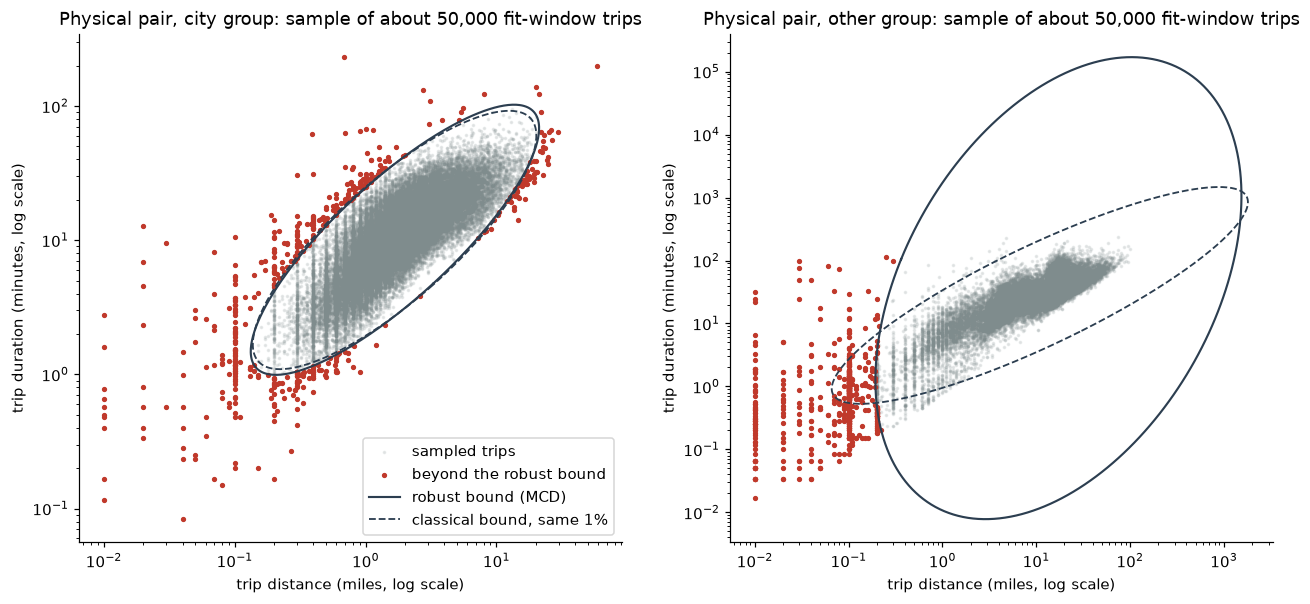

In [20]:
def ellipse_points(centre, covariance, bound, n=400):
    """Points where the squared Mahalanobis distance equals the bound."""
    values, vectors = np.linalg.eigh(covariance)
    angle = np.linspace(0, 2 * np.pi, n)
    circle = np.vstack([np.cos(angle), np.sin(angle)]) * np.sqrt(bound * values)[:, None]
    return centre + (vectors @ circle).T


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, group in zip(axes, ["city", "other"]):
    X = pair_samples["physical"].query("pair_group == @group")[["x1", "x2"]].to_numpy()
    fit = pair_fits["physical"][group]
    robust_d2 = squared_distance(X, fit["location"], fit["inverse"])
    classical_covariance = np.cov(X, rowvar=False)
    classical_d2 = squared_distance(X, X.mean(axis=0), np.linalg.inv(classical_covariance))
    flagged = robust_d2 > pair_ks["physical"][group]

    robust_edge = ellipse_points(fit["location"], np.linalg.inv(fit["inverse"]), pair_ks["physical"][group])
    classical_edge = ellipse_points(X.mean(axis=0), classical_covariance, np.quantile(classical_d2, 0.99))
    ax.scatter(np.exp(X[~flagged, 0]), np.exp(X[~flagged, 1]), s=2, alpha=0.15, color="#7f8c8d", label="sampled trips")
    ax.scatter(np.exp(X[flagged, 0]), np.exp(X[flagged, 1]), s=6, color=ANOMALY_COLOR, label="beyond the robust bound")
    ax.plot(np.exp(robust_edge[:, 0]), np.exp(robust_edge[:, 1]), color="#2c3e50", linewidth=1.4,
            label="robust bound (MCD)")
    ax.plot(np.exp(classical_edge[:, 0]), np.exp(classical_edge[:, 1]), color="#2c3e50", linewidth=1.2,
            linestyle="--", label="classical bound, same 1%")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"Physical pair, {group} group: sample of about 50,000 fit-window trips")
    ax.set_xlabel("trip distance (miles, log scale)")
    ax.set_ylabel("trip duration (minutes, log scale)")
axes[0].legend(loc="lower right")
fig.savefig(FIG_DIR / "07_physical_pair_robust_vs_classical.png", bbox_inches="tight")
plt.show()

The chart shows how differently the two groups behave. In the city group the robust and classical bounds almost coincide. Both are a diagonal ellipse along which distance and duration grow together; this is why the two methods' most extreme 1% overlap at 91.984%. Most red points outside the bound are on the left, on trips shorter than 0.3 miles, especially those whose duration is long for their distance. At the bottom right there are also trips that are very short for their distance, that is, very fast trips.

In the other group the two bounds are very different. The classical bound follows the diagonal spread of the points. The robust bound, however, is an almost vertical and very large ellipse; it encloses even trips lasting tens of thousands of minutes. All flagged trips in this group are on the left, among records shorter than about 0.2 miles; there is also a crowded column at 0.01 miles. The group's most extreme 1% consists entirely of these short-distance records, and the bound lands on their edge. This is why this group's bound is 639.927 in the table in 7.1. In this group the robust method works in practice like a lower bound on distance. It finds the very short records; that 74.028% of the trips flagged in this group carry a Task 2 flag in 7.1 is consistent with this. It cannot, however, see a trip whose distance is normal but whose duration is unusual.

**The robust covariance works well for city trips; in a mixed group combining Newark and outside-NYC trips, a single ellipse suits neither method.** I added splitting these groups to the next steps in Section 12.

### 7.3 Testing with a known error: the spring-forward night

Since there is no ground truth, I tested the methods with a known data error. On the spring-forward nights (in the 3.3 list), the duration is computed as the difference of two local-time timestamps, so trips spanning 02:00 come out one hour too long (Task 2, 13.2). These trips have a normal distance and a long duration. Since distance and duration are inconsistent with each other, the physical pair should catch them.

I found these trips from the recorded duration: trips that start before 02:00 and, according to the recorded duration, end after 03:00. On that night the clock jumped from 02:00 to 03:00, so all of these trips span 02:00. I wrote the decision rule before the test: the test passes if the physical pair flags at least half of these trips and catches more than the univariate bounds.

In [21]:
x1, x2, condition, group_sql = PAIR_COLUMNS["physical"]
spring_forward = (
    "CAST(tpep_pickup_datetime AS DATE) IN (DATE '2015-03-08', DATE '2016-03-13') "
    "AND hour(tpep_pickup_datetime) < 2 "
    "AND tpep_pickup_datetime + to_seconds(CAST(duration_min * 60 AS BIGINT)) "
    ">= CAST(CAST(tpep_pickup_datetime AS DATE) AS TIMESTAMP) + INTERVAL 3 HOUR")

dst_trips = f"""
    SELECT *,
        {mahalanobis_sql(pair_fits['physical'])} > {group_case('pair_group', pair_ks['physical'])} AS physical_flag,
        {univariate_flag_sql('trip_distance')}                                               AS distance_flag,
        {univariate_flag_sql('duration_min')}                                                AS duration_flag
    FROM (SELECT {SEGMENT_GROUP} AS segment, {group_sql} AS pair_group, trip_distance, duration_min,
                 {x1} AS x1, {x2} AS x2
          FROM matrix WHERE {condition} AND {spring_forward})"""

dst_test = con.execute(f"""
    SELECT
        COUNT(*)                                                                              AS trips,
        median(duration_min)                                                                  AS median_duration_min,
        100.0 * AVG(CAST(distance_flag AS INTEGER))                                           AS distance_pct,
        100.0 * AVG(CAST(duration_flag AS INTEGER))                                           AS duration_pct,
        100.0 * AVG(CAST(distance_flag OR duration_flag AS INTEGER))                          AS univariate_pct,
        100.0 * AVG(CAST(physical_flag AS INTEGER))                                           AS physical_pct,
        100.0 * AVG(CAST(physical_flag AND NOT (distance_flag OR duration_flag) AS INTEGER))  AS only_physical_pct,
        100.0 * AVG(CAST((distance_flag OR duration_flag) AND NOT physical_flag AS INTEGER))  AS only_univariate_pct,
        100.0 * AVG(CAST(physical_flag OR distance_flag OR duration_flag AS INTEGER))         AS either_pct
    FROM ({dst_trips})
""").df().T.rename(columns={0: "value"})

dst_test.round(3)

,value
trips,8979.000
median_duration_min,75.767
distance_pct,2.918
duration_pct,59.116
univariate_pct,59.194
physical_pct,78.461
only_physical_pct,37.421
only_univariate_pct,18.153
either_pct,96.614


Before interpreting the result I checked one thing. The physical pair was fitted only on trips with distance above 0. The univariate duration bound in Section 6, however, was computed from all trips with a duration, including those with zero or missing distance. That the two methods were fitted on different groups of trips could affect the comparison. Since almost all DST trips are city trips, I computed the city duration bound separately for the two groups and looked at how many DST trips exceed each bound.

In [22]:
city_duration = "in_fit_window AND trip_segment = 'city' AND duration_min > 0"
populations = {
    "all trips with a duration (Section 6)": "",
    "trips with distance > 0 (physical pair)": "AND trip_distance > 0",
}

bound_rows = []
for label, extra in populations.items():
    v = con.execute(f"SELECT ln(duration_min) FROM matrix "
                    f"WHERE {city_duration} {extra} AND {TRIP_HASH} % 200 = 0").df().iloc[:, 0].to_numpy()
    median = np.median(v)
    robust_sd = 1.4826 * np.median(np.abs(v - median))
    k = np.quantile(np.abs(v - median) / robust_sd, 0.99)
    upper = np.exp(median + k * robust_sd)
    dst_flagged = con.execute(f"SELECT 100.0 * AVG(CAST(duration_min > {sql_number(upper)} AS INTEGER)) "
                              f"FROM ({dst_trips}) WHERE segment = 'city'").fetchone()[0]
    bound_rows.append({"population": label, "sample_rows": len(v), "k": k,
                       "upper_bound_min": upper, "dst_city_trips_above_pct": dst_flagged})

pd.DataFrame(bound_rows).set_index("population").round(3)

,sample_rows,k,upper_bound_min,dst_city_trips_above_pct
population,,,,
all trips with a duration (Section 6),982940,2.821,73.62,59.543
trips with distance > 0 (physical pair),979270,2.670,65.94,93.474


The rule passed: the physical pair flags 78.461% of the DST trips. That is more than half and higher than the share flagged by the univariate bounds (59.194%). The distance bound catches only 2.918% of these trips; as expected, their distance is normal.

But the second table shows how fragile this result is. When I compute the city duration bound from the same group of trips as the physical pair, that is, trips with distance above 0, the bound falls from 73.62 minutes to 65.94 minutes. This bound catches 93.474% of the DST trips instead of 59.543%. The difference between the two groups is very small: 982,940 versus 979,270 trips in the sample. These few trips with zero distance use up part of the 1% share and push the bound up. Had the univariate bound been built this way, it would have done better than the multivariate method on this error.

So I cannot say "the multivariate method catches this error better". What I can say is that the two methods catch different trips: 37.421% of the trips are caught only by the physical pair and 18.153% only by the univariate bounds. Together they find 96.614%.

**On a known data error the two methods complement each other: neither is enough on its own, together they find 96.614% of the error.** That a percentile bound is so sensitive to the group of trips it is computed from also shows that it must be stated clearly which trips each method's bound comes from.

### 7.4 What the multivariate methods show

- Whether a trip that is anomalous in one variable stays anomalous when two columns are evaluated together depends on the trip type. In the city about half of these trips stay anomalous (46.738% in the physical pair, 49.965% in the economic pair). In the airport groups most stay anomalous (100% at JFK in the physical pair).
- The physical pair finds new trips. 58.869% of the city trips it flags are also flagged by a univariate bound; the rest have a distance and duration that are normal on their own but inconsistent together. The economic pair mostly finds what the univariate bounds find.
- The normal assumption does not hold in two dimensions either. I took the bounds from each group's own 1%, not from the chi-square distribution. The robust covariance gives results similar to the classical one in most groups. In the mixed group that combines Newark and outside NYC, however, a single ellipse suits neither method.
- The relationship between distance and duration stays almost the same in both periods. The economic pair, which rests on speed and fare, is affected by the 2016 shift.
- On a known data error, the spring-forward night, the two methods complement each other. Which one looks better depends on which trips the univariate bound is computed from.
- All methods so far looked at single trips. Some anomalies, however, appear not in one trip but in many trips together over time: sudden drops in demand, or errors increasing in one vendor's records from a certain day on. I handled these in Section 8.

## 8. Time-based anomalies

The methods so far looked at single trips. In this section I aggregated trips over time and checked whether the totals deviate from what is expected. I did this at three levels: city-wide hourly trip counts (8.1), hourly trip counts by zone (8.2) and daily error rates by vendor (8.3).

### 8.1 City-wide hourly demand

Whether the number of trips in an hour is normal depends on the hour of the day, the day of the week and the decline that runs through the two years. I used two methods that account for these three effects. Both work with the logarithm of the trip count, because while volume falls over the two years the weekly pattern stays the same in proportion.

The retrospective decomposition splits the series into trend, weekly pattern and residual. I found the trend with a centred one-week median and the weekly pattern with the median of each hour of the week. I computed the trend in two passes: first a rough trend, then a second trend on the series with the weekly pattern removed. This is the logic of STL decomposition built with medians. statsmodels is not installed in this environment, so I wrote the steps out explicitly; this also kept every step visible. Since the centred window also sees the future, this method suits analysing the past, not a real-time alarm.

The real-time method looks only at the past: the expected value for each hour is the median of the same hour of the week over the last few weeks. In both methods I standardised the residual with the median and MAD of the fit-window residuals. Consistent with earlier sections, I took as the bound the |z| value that flags 1% of fit-window hours.

Since there is no ground truth, I evaluated the methods with the event list I wrote before the results in 3.3. For the real-time method I tried windows of 4, 8 and 12 weeks. I wrote the decision rule in advance: the window that flags the largest part of the event hours is chosen; if the difference is below 2 points, 8 weeks is chosen.

In [23]:
from pandas.tseries.holiday import USFederalHolidayCalendar

hourly_trips = con.execute("""
    SELECT date_trunc('hour', tpep_pickup_datetime) AS hour_start, COUNT(*) AS trips
    FROM matrix GROUP BY 1 ORDER BY 1
""").df().set_index("hour_start")["trips"]
log_trips = np.log(hourly_trips.astype(float))
hour_of_week = pd.Series(log_trips.index.dayofweek * 24 + log_trips.index.hour, index=log_trips.index)
in_fit_hour = log_trips.index < pd.Timestamp(FIT_END)

days = pd.Series(log_trips.index.normalize(), index=log_trips.index)
holidays = set(USFederalHolidayCalendar().holidays("2015-01-01", "2016-12-31")) | {
    pd.Timestamp("2015-11-03"), pd.Timestamp("2016-11-08")}
dst_nights = {pd.Timestamp(d) for d in ["2015-03-08", "2015-11-01", "2016-03-13", "2016-11-06"]}
event_hours = pd.DataFrame({
    "blizzard": days.isin([pd.Timestamp("2016-01-23"), pd.Timestamp("2016-01-24")]),
    "dst": days.isin(dst_nights) & log_trips.index.hour.isin([1, 2]),
    "holiday": days.isin(holidays),
})
event_hours["any"] = event_hours.any(axis=1)

In [24]:
def robust_z(residual):
    """Residual standardised by the median and MAD of the fit window."""
    centre = residual[in_fit_hour].median()
    return (residual - centre) / (1.4826 * (residual[in_fit_hour] - centre).abs().median())


def decomposition_z(series):
    """Retrospective: two-pass weekly median trend and an hour-of-week profile fitted on the fit window."""
    rough = series.rolling(168, center=True, min_periods=84).median()
    profile = (series - rough)[in_fit_hour].groupby(hour_of_week[in_fit_hour]).median()
    trend = (series - hour_of_week.map(profile)).rolling(168, center=True, min_periods=84).median()
    profile = (series - trend)[in_fit_hour].groupby(hour_of_week[in_fit_hour]).median()
    return robust_z(series - trend - hour_of_week.map(profile))


def trailing_z(series, weeks):
    """Real time: median of the same hour of week over the previous weeks."""
    baseline = series.groupby(hour_of_week).transform(
        lambda s: s.shift(1).rolling(weeks, min_periods=4).median())
    return robust_z(series - baseline)

In [25]:
hourly_methods = {"decomposition": decomposition_z(log_trips)}
hourly_methods.update({f"trailing_{weeks}w": trailing_z(log_trips, weeks) for weeks in [4, 8, 12]})

hourly_rows, hourly_k = [], {}
for name, z in hourly_methods.items():
    hourly_k[name] = z[in_fit_hour].abs().quantile(0.99)
    flagged = z.abs() > hourly_k[name]
    hourly_rows.append({
        "method": name, "k": hourly_k[name],
        "flagged_fit": int(flagged[in_fit_hour].sum()), "flagged_holdout": int(flagged[~in_fit_hour].sum()),
        "event_hours_flagged_pct": 100 * flagged[event_hours["any"]].mean(),
        "blizzard_flagged_pct": 100 * flagged[event_hours["blizzard"]].mean(),
        "dst_flagged_pct": 100 * flagged[event_hours["dst"]].mean(),
        "holiday_flagged_pct": 100 * flagged[event_hours["holiday"]].mean(),
        "flagged_on_events_pct": 100 * event_hours.loc[flagged, "any"].mean(),
        "drops_pct_of_flagged": 100 * (z[flagged] < 0).mean(),
    })

hourly_comparison = pd.DataFrame(hourly_rows).set_index("method")
trailing = hourly_comparison.filter(like="trailing", axis=0)["event_hours_flagged_pct"]
RULES["hourly_trailing_weeks"] = 8 if trailing.max() - trailing["trailing_8w"] < 2 else int(trailing.idxmax().split("_")[1][:-1])
RULES["hourly_flag_k"] = hourly_k

hourly_comparison.round(3)

,k,flagged_fit,flagged_holdout,event_hours_flagged_pct,blizzard_flagged_pct,dst_flagged_pct,holiday_flagged_pct,flagged_on_events_pct,drops_pct_of_flagged
method,,,,,,,,,
decomposition,11.154,132,33,19.349,64.583,37.5,14.962,68.485,77.576
trailing_4w,10.143,125,55,19.521,62.500,37.5,15.341,63.333,82.222
trailing_8w,9.605,125,55,20.034,66.667,37.5,15.530,65.000,83.889
trailing_12w,8.557,125,57,20.034,66.667,37.5,15.530,64.286,83.516


The window rule chose 8 weeks. The share of event hours flagged is 19.521% with the 4-week window and 20.034% with the 8- and 12-week windows; the difference is below 2 points. The window length barely changes the result.

The most important result is in the last two columns. About two thirds of the flagged hours fall on the event list I wrote without seeing the results: 68.485% for the retrospective decomposition and 65.0% for the 8-week real-time method. On data without ground truth, a method finding events known in advance is the strongest evidence that it measures the right thing. Between 77.576% and 83.889% of the flagged hours are drops. Demand anomalies in this data are mostly sudden drops.

The event types differ a lot. About two thirds of the blizzard-day hours are flagged (between 62.5% and 66.667%). I defined the storm as all hours of the two days; since I did not verify the exact hours of the travel ban, unaffected hours also enter this definition and the flagged share may look lower than it is. 37.5% of the 01:00 and 02:00 hours of the DST nights are flagged. Only about 15% of holiday hours are flagged; most hours of holidays stay within the bound.

The two methods behave differently in the holdout: the retrospective decomposition flags 33 hours, the real-time method 55. One reason may be that the real-time method looks only at the past and adapts to a change in demand only within a few weeks.

**I used the 8-week window for the real-time method.** About a third of the flagged hours are not in the event list. I looked at them at the end of 8.1.

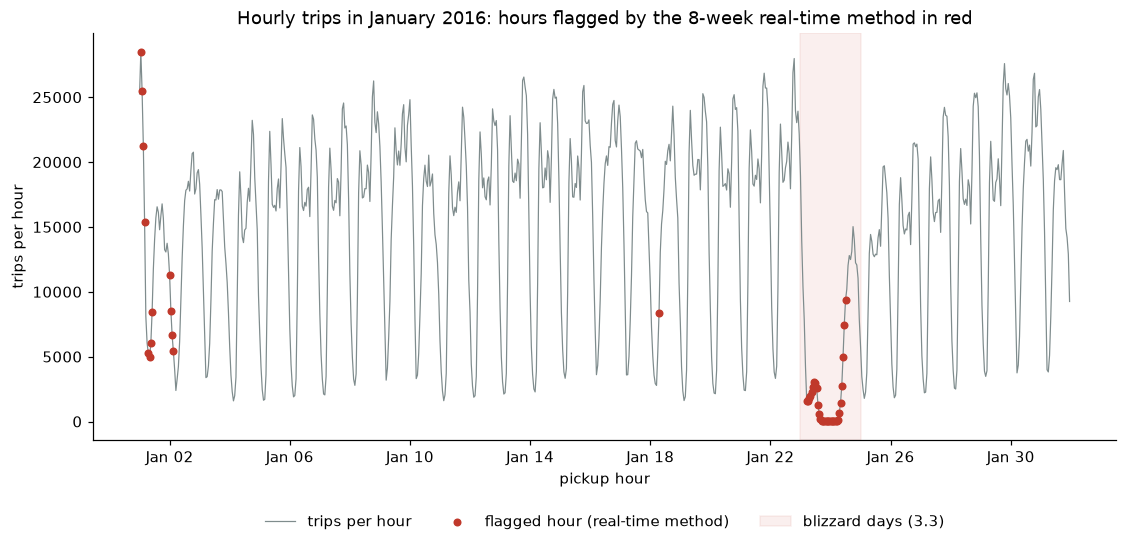

In [26]:
import matplotlib.dates as mdates

in_january = (hourly_trips.index >= "2016-01-01") & (hourly_trips.index < "2016-02-01")
realtime_z = hourly_methods["trailing_8w"]
flagged_january = (realtime_z.abs() > hourly_k["trailing_8w"]) & in_january

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(hourly_trips.index[in_january], hourly_trips[in_january],
        color="#7f8c8d", linewidth=0.8, label="trips per hour")
ax.scatter(hourly_trips.index[flagged_january], hourly_trips[flagged_january],
           color=ANOMALY_COLOR, s=18, zorder=3, label="flagged hour (real-time method)")
ax.axvspan(pd.Timestamp("2016-01-23"), pd.Timestamp("2016-01-25"),
           color=ANOMALY_COLOR, alpha=0.08, label="blizzard days (3.3)")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_title("Hourly trips in January 2016: hours flagged by the 8-week real-time method in red")
ax.set_xlabel("pickup hour")
ax.set_ylabel("trips per hour")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
fig.savefig(FIG_DIR / "08_hourly_trips_january_2016.png", bbox_inches="tight")
plt.show()

In [27]:
realtime_baseline = log_trips.groupby(hour_of_week).transform(
    lambda s: s.shift(1).rolling(RULES["hourly_trailing_weeks"], min_periods=4).median())
realtime_flagged = realtime_z.abs() > hourly_k["trailing_8w"]
unexplained = realtime_flagged & ~event_hours["any"]

pd.DataFrame({
    "weekday": log_trips.index.day_name(),
    "trips": hourly_trips,
    "expected_trips": np.exp(realtime_baseline).round(0),
    "z": realtime_z,
})[unexplained].assign(abs_z=lambda d: d["z"].abs()).nlargest(15, "abs_z").drop(columns="abs_z").round(2)

,weekday,trips,expected_trips,z
hour_start,,,,
2015-12-26 02:00:00,Saturday,3177,17480.0,-22.47
2015-12-26 03:00:00,Saturday,2493,12593.0,-21.34
2015-12-26 01:00:00,Saturday,4358,21093.0,-20.77
2015-12-26 04:00:00,Saturday,2072,8030.0,-17.84
2015-12-26 00:00:00,Saturday,6248,23845.0,-17.63
2016-12-25 03:00:00,Sunday,3239,12242.0,-17.50
2016-12-25 02:00:00,Sunday,4552,15990.0,-16.53
2015-11-27 07:00:00,Friday,5662,19074.0,-15.98
2016-11-25 07:00:00,Friday,5487,17710.0,-15.42


All 15 most extreme hours not in the event list fall right before or after a holiday. The first hours of 26 December 2015 are Christmas night: Christmas fell on a Friday that year, and since I defined holidays as calendar days, the hours after midnight did not enter the list. In 2016 Christmas fell on a Sunday. The federal calendar moves this holiday to Monday 26 December (Task 2, 5.4), so 25 December was not in my list. 27 November 2015 and 25 November 2016 are the Fridays after Thanksgiving. These days are not federal holidays, yet between 06:00 and 08:00 the number of trips stays at about a third of what is expected.

These hours are missing from the list because I defined holidays as calendar days when I prepared the event list. That definition did not cover the hours after midnight on holiday nights, the years in which the holiday moved to another day, or the days after holidays. **I did not extend the list after seeing the results; had I done so, I would have overstated the share of flagged hours that fall on events.** So the roughly 65% I found in 8.1 is a lower bound of the true share.

### 8.2 Hourly demand by zone

The city-wide hourly series may not see an event in a single zone. If demand falls in one zone while it rises in another, the city total does not change. So I also applied the same real-time method by zone. I did not look at every zone; I picked the zones with an average of at least 5 trips per hour in the fit window. In sparser zones hourly counts are mostly 0, 1 or 2, so an anomaly cannot be told apart from random fluctuation. Since some hours have no trips at all, I applied the logarithm to the trip count plus one. I computed each zone's scale and bound from that zone's own fit window; the bound is again 1% of hours.

With a bound that flags 1% of hours in each zone, every zone flags about 1% even if nothing happens there. So I separately tested whether the flags are just noise. I called zone flags in hours that are normal city-wide local flags. A real local event usually lasts a few hours or affects several zones together; noise is scattered. I measured how many local flags appear together with an adjacent hour in the same zone, and how many with at least three other zones in the same hour. I compared this with the share expected if the flags were independent of each other. I wrote the decision rule in advance: if one of these two shares is at least 5 times the share under independence, there is more than noise in the local flags.

In [28]:
from scipy.stats import binom

RULES["zone_min_trips_per_hour"] = 5
fit_hours = int(in_fit_hour.sum())
zone_density = con.execute(f"""
    SELECT PULocationID AS zone, COUNT(*) / {fit_hours} AS trips_per_hour
    FROM matrix WHERE in_fit_window AND PULocationID NOT IN (264, 265) GROUP BY 1
""").df()
busy = zone_density["trips_per_hour"] >= RULES["zone_min_trips_per_hour"]
busy_zones = zone_density.loc[busy, "zone"].tolist()

zone_counts = (con.execute(f"""
    SELECT PULocationID AS zone, date_trunc('hour', tpep_pickup_datetime) AS hour_start, COUNT(*) AS trips
    FROM matrix WHERE PULocationID IN ({', '.join(map(str, busy_zones))}) GROUP BY 1, 2
""").df().pivot(index="hour_start", columns="zone", values="trips").reindex(log_trips.index).fillna(0))

log_zone = np.log1p(zone_counts)
zone_baseline = log_zone.groupby(hour_of_week.to_numpy()).transform(
    lambda s: s.shift(1).rolling(RULES["hourly_trailing_weeks"], min_periods=4).median())
zone_residual = log_zone - zone_baseline
zone_centre = zone_residual[in_fit_hour].median()
zone_scale = 1.4826 * (zone_residual[in_fit_hour] - zone_centre).abs().median()
zone_z = (zone_residual - zone_centre) / zone_scale
zone_flag = zone_z.abs() > zone_z[in_fit_hour].abs().quantile(0.99)

local_flag = zone_flag & ~realtime_flagged.to_numpy()[:, None]
neighbours = zone_flag.shift(1, fill_value=False) | zone_flag.shift(-1, fill_value=False)
other_zones = zone_flag.sum(axis=1).to_numpy()[:, None] - 1
flag_rate = zone_flag.to_numpy().mean()
local_count = local_flag.to_numpy().sum()
temporal_pct = 100 * (local_flag & neighbours).to_numpy().sum() / local_count
spatial_pct = 100 * (local_flag & (other_zones >= 3)).to_numpy().sum() / local_count
temporal_expected = 100 * (1 - (1 - flag_rate) ** 2)
spatial_expected = 100 * binom.sf(2, len(busy_zones) - 1, flag_rate)
RULES["zone_local_has_structure"] = max(temporal_pct / temporal_expected, spatial_pct / spatial_expected) >= 5

zero_hours = 100 * (zone_counts[in_fit_hour] == 0).mean()
pd.Series({
    "zones": len(busy_zones),
    "share of fit trips in these zones (%)": 100 * zone_density.loc[busy, "trips_per_hour"].sum()
                                             / zone_density["trips_per_hour"].sum(),
    "zero-trip fit hours, median zone (%)": zero_hours.median(),
    "zero-trip fit hours, worst zone (%)": zero_hours.max(),
    "smallest robust scale": zone_scale.min(),
    "flagged zone-hours, fit": int(zone_flag[in_fit_hour].to_numpy().sum()),
    "flagged zone-hours, holdout": int(zone_flag[~in_fit_hour].to_numpy().sum()),
    "local share of flags (%)": 100 * local_count / zone_flag.to_numpy().sum(),
    "flags on 3.3 event hours (%)": 100 * (zone_flag & event_hours["any"].to_numpy()[:, None]).to_numpy().sum()
                                    / zone_flag.to_numpy().sum(),
    "temporal cluster, observed (%)": temporal_pct,
    "temporal cluster, independent (%)": temporal_expected,
    "spatial cluster, observed (%)": spatial_pct,
    "spatial cluster, independent (%)": spatial_expected,
}, name="value").to_frame().round(3)

,value
zones,88.000
share of fit trips in these zones (%),99.452
"zero-trip fit hours, median zone (%)",0.152
"zero-trip fit hours, worst zone (%)",18.487
smallest robust scale,0.124
"flagged zone-hours, fit",10930.000
"flagged zone-hours, holdout",4645.000
local share of flags (%),51.352
flags on 3.3 event hours (%),43.640
"temporal cluster, observed (%)",33.471


The 88 selected zones cover 99.452% of the trips in the fit window. Zero-trip hours are very few in most zones (0.152% in the median zone); in the sparsest zone 18.487% of hours are empty. The scale is above zero in every zone, so a bound could be computed for each zone.

10,930 zone-hours were flagged in the fit window. 51.352% of them are in hours that are normal city-wide. The clustering test shows these local flags are not random. 33.471% of local flags appear together with an adjacent hour in the same zone; if the flags were independent this rate would be 2.007%, so the observed rate is about 17 times higher. 36.009% appear together with at least three other zones in the same hour. Under independence this rate would be 5.832%, so the observed rate is about 6 times higher. **The local flags are not random; they point to events that last a few hours or affect several zones together, and these events are not visible city-wide.**

43.64% of the flags fall on the event hours in 3.3; city-wide this rate was about two thirds. This difference is expected, because the event list consists only of events affecting the whole city. I cannot tell from this data which events cause the local flags. That would need external data such as an events calendar, road closures or weather.

In [29]:
zone_names = pd.read_csv(ZONE_LOOKUP).set_index("LocationID")["Zone"]
expected_zone_trips = np.expm1(zone_baseline)

event_rows = []
for zone in local_flag.columns:
    flagged = local_flag[zone]
    run_id = (flagged != flagged.shift()).cumsum()
    for _, run in flagged[flagged].groupby(run_id[flagged]):
        hours = run.index
        z = zone_z.loc[hours, zone]
        event_rows.append({
            "zone": zone_names.get(zone, zone),
            "start": hours[0].strftime("%Y-%m-%d %H:%M"),
            "hours": len(hours),
            "direction": "drop" if z.mean() < 0 else "spike",
            "trips": int(zone_counts.loc[hours, zone].sum()),
            "expected trips": int(round(expected_zone_trips.loc[hours, zone].sum())),
            "largest |z|": round(z.abs().max(), 2),
        })

local_events = pd.DataFrame(event_rows)
local_events.sort_values(["hours", "largest |z|"], ascending=False).head(10).reset_index(drop=True)

,zone,start,hours,direction,trips,expected trips,largest |z|
0,Times Sq/Theatre District,2016-12-31 07:00,17,drop,3028,8860,11.33
1,Midtown Center,2015-09-24 12:00,12,drop,2774,10702,13.47
2,Sunnyside,2015-02-02 09:00,12,spike,1268,267,7.74
3,Times Sq/Theatre District,2015-12-31 14:00,11,drop,2000,7237,11.62
4,Upper East Side North,2016-07-04 11:00,9,drop,2525,7596,7.69
5,Williamsburg (North Side),2016-10-06 09:00,8,spike,444,41,7.88
6,Penn Station/Madison Sq West,2015-09-25 13:00,7,drop,1166,4287,12.51
7,Meatpacking/West Village West,2015-06-28 15:00,7,drop,582,2146,9.45
8,Financial District South,2015-12-24 19:00,7,drop,192,697,7.20
9,Garment District,2015-11-26 10:00,6,drop,603,2226,12.34


Of the ten longest local events, eight are drops and two are spikes. Some of them match known events. Both New Year's Eves appear for Times Square: on 31 December 2016 for 17 hours and on 31 December 2015 for 11 hours the number of trips stays far below expectation; in 2016 there were 3,028 trips instead of the expected 8,860. The area is closed to traffic every year for the New Year's celebration. The drops in Midtown Center on 24 September 2015 and in Penn Station/Madison Sq West on 25 September 2015 fall on the same days and areas as the road closures the NYPD announced during Pope Francis's visit to New York ([ABC7 report](https://abc7ny.com/980191/)): Madison Avenue between 47th and 57th Streets on 24 September and the area around Madison Square Garden on 25 September. The list also has Upper East Side North on 4 July, Financial District South on Christmas Eve and the Garment District on Thanksgiving morning.

I do not know the cause of the two spikes. In Sunnyside on 2 February 2015 there were 1,268 trips over 12 hours instead of the expected 267, and in Williamsburg (North Side) on 6 October 2016 444 trips over 8 hours instead of the expected 41. A local cause such as a transit outage is possible, but I cannot confirm it with this data.

I looked for these explanations after seeing the results. As I wrote in 3.3, such matching can make a method look better than it is. So these examples do not prove the method's success; they only show that local flags can correspond to real, local events. **Zone-level flags can catch road closures and crowded events that are not visible city-wide; confirming this systematically needs an events calendar.**

### 8.3 Daily error rates by vendor

A change in the software or a system failure at one of the two vendors producing the records (VendorID 1 and 2) looks like a small error in single records. When it appears in many records on the same day, it forms a collective anomaly. To catch this, I computed the daily flag rate for each vendor and each of Task 2's rule flags: two vendors and ten flags, twenty daily series in total. I applied the daily version of the real-time method from 8.1 to each series: the expected value is the median of the last 56 days, the scale is the robust MAD of the fit-window deviations, and the bound is 1% of fit-window days.

I wrote the decision rules before the results. A series whose scale is zero, that is, a flag almost never seen at that vendor, cannot be scored and stays outside the method. I validated the method with the 3.3 events. Since the duration computation breaks on the two fall-back nights, these days must be flagged in the `is_duration_invalid` series for at least one vendor; if not, the method misses a known event. I also showed, for information, how often holidays are flagged in the `is_extra_mismatch` series.

In [30]:
RULES["daily_trailing_days"] = 56

vendor_daily = con.execute(f"""
    SELECT CAST(tpep_pickup_datetime AS DATE) AS day, VendorID AS vendor,
        {", ".join(f"100.0 * AVG(CAST(COALESCE({flag}, false) AS INTEGER)) AS {flag}" for flag in RULE_FLAGS)}
    FROM matrix WHERE VendorID IN (1, 2) GROUP BY 1, 2
""").df().melt(id_vars=["day", "vendor"], var_name="flag", value_name="rate")
vendor_daily["day"] = pd.to_datetime(vendor_daily["day"])
vendor_daily = vendor_daily.sort_values(["vendor", "flag", "day"]).reset_index(drop=True)
vendor_daily["in_fit"] = vendor_daily["day"] < pd.Timestamp(FIT_END)


def score_daily(group):
    """Median of the previous days as the baseline; robust scale and 1% threshold from the fit window."""
    days_back = RULES["daily_trailing_days"]
    baseline = group["rate"].shift(1).rolling(days_back, min_periods=days_back // 2).median()
    residual = group["rate"] - baseline
    fit_residual = residual[group["in_fit"]].dropna()
    centre = fit_residual.median()
    scale = 1.4826 * (fit_residual - centre).abs().median()
    z = (residual - centre) / scale if scale > 0 else residual * np.nan
    return pd.DataFrame({"baseline": baseline, "z": z, "scale": scale,
                         "k": z[group["in_fit"]].abs().quantile(0.99)}, index=group.index)


vendor_daily = vendor_daily.join(vendor_daily.groupby(["vendor", "flag"], group_keys=False).apply(score_daily))
vendor_daily["flagged"] = vendor_daily["z"].abs() > vendor_daily["k"]

not_scored = vendor_daily.groupby(["vendor", "flag"])["scale"].first().eq(0)
fall_back = (vendor_daily["flag"] == "is_duration_invalid") & vendor_daily["day"].isin(
    [pd.Timestamp("2015-11-01"), pd.Timestamp("2016-11-06")])
holiday_extra = vendor_daily[(vendor_daily["flag"] == "is_extra_mismatch")
                             & vendor_daily["day"].isin(holidays) & vendor_daily["z"].notna()]
nights_caught = vendor_daily[fall_back].groupby("day")["flagged"].any()
RULES["vendor_daily_dst_check_passed"] = bool(nights_caught.all())

pd.Series({
    "vendor-flag series": len(not_scored),
    "series not scored (zero scale)": ", ".join(f"V{v} {f.removeprefix('is_')}" for v, f in not_scored[not_scored].index),
    "flagged vendor-flag-days, fit": int(vendor_daily.loc[vendor_daily["in_fit"], "flagged"].sum()),
    "flagged vendor-flag-days, holdout": int(vendor_daily.loc[~vendor_daily["in_fit"], "flagged"].sum()),
    "fall-back nights caught by at least one vendor (of 2)": int(nights_caught.sum()),
    "smallest z on those vendor-nights": round(vendor_daily.loc[fall_back, "z"].min(), 3),
    "scored holidays flagged in is_extra_mismatch, vendor 1 (%)":
        round(100 * holiday_extra.loc[holiday_extra["vendor"] == 1, "flagged"].mean(), 3),
    "scored holidays flagged in is_extra_mismatch, vendor 2 (%)":
        round(100 * holiday_extra.loc[holiday_extra["vendor"] == 2, "flagged"].mean(), 3),
}, name="value").to_frame()

,value
vendor-flag series,20
series not scored (zero scale),"V1 amount_mismatch, V2 ratecode_invalid"
"flagged vendor-flag-days, fit",108
"flagged vendor-flag-days, holdout",44
fall-back nights caught by at least one vendor (of 2),2
smallest z on those vendor-nights,29.333
"scored holidays flagged in is_extra_mismatch, vendor 1 (%)",10.0
"scored holidays flagged in is_extra_mismatch, vendor 2 (%)",30.0


In [31]:
(vendor_daily[vendor_daily["flagged"]]
 .assign(abs_z=lambda d: d["z"].abs(), day=lambda d: d["day"].dt.date)
 .nlargest(15, "abs_z")[["day", "vendor", "flag", "rate", "baseline", "z"]]
 .round(3)
 .reset_index(drop=True))

,day,vendor,flag,rate,baseline,z
0,2016-04-21,1,is_ratecode_invalid,4.215,0.005,1820.902
1,2016-06-08,2,is_amount_mismatch,0.636,0.001,318.854
2,2016-06-27,2,is_amount_mismatch,0.513,0.003,256.127
3,2016-06-16,2,is_amount_mismatch,0.478,0.002,239.136
4,2016-07-01,2,is_amount_mismatch,0.455,0.004,226.618
5,2015-07-31,1,is_ratecode_invalid,0.506,0.005,217.074
6,2016-09-30,2,is_amount_mismatch,0.817,0.392,213.702
7,2016-06-28,2,is_amount_mismatch,0.421,0.003,210.031
8,2016-04-21,1,is_duration_invalid,4.417,0.212,209.493
9,2016-07-04,2,is_amount_mismatch,0.419,0.005,208.122


The validation passed. Both fall-back nights were flagged for at least one vendor, and the smallest z value on these nights is 29.333; the method finds the known event by a clear margin. On holidays the `is_extra_mismatch` series was flagged on 10% of the scored holidays for Vendor 1 and 30% for Vendor 2. This matches what Task 2 found in 5.4: the share of meters that keep charging the peak surcharge on holidays differs by vendor.

The most extreme days show two kinds of event. The first is two days at Vendor 1. On 21 April 2016 three flags rise on the same day: the rate-code error rate goes from 0.005% to 4.215%, the invalid-duration rate from 0.212% to 4.417% and the missing-distance rate from 0.702% to 4.954%. On 31 July 2015 the rate-code error rate goes from 0.005% to 0.506%. Both days look like a system problem at one vendor affecting several fields at once.

The second is Vendor 2's `is_amount_mismatch` series. At the start of June 2016 the rate rises from near zero to around 0.4–0.6% and stays at this level for weeks. This is not a one-day event but a permanent change. The real-time method's expected value adapts to the new level only within a few weeks, so many days from 8 June to early July are flagged. On 30 September, with the expected value already up to 0.392%, the rate jumps to 0.817% and this day is flagged too.

There is also an event the method cannot see. In 4.1 I saw that the `is_amount_mismatch` rate is higher in the fit window than in the holdout. Its source is not in this list, because Vendor 1's `is_amount_mismatch` series could not be scored as its scale is zero. I looked at this series separately.

In [32]:
con.execute("""
    SELECT
        CASE WHEN tpep_pickup_datetime < '2015-01-05' THEN '1 fit window, 1-4 Jan 2015'
             WHEN in_fit_window THEN '2 fit window, rest'
             ELSE '3 holdout' END                                                       AS period,
        COUNT(*)                                                                        AS trips,
        100.0 * AVG(CAST(COALESCE(is_amount_mismatch, false) AS INTEGER))               AS all_vendors_pct,
        100.0 * AVG(CAST(COALESCE(is_amount_mismatch, false) AS INTEGER))
              FILTER (WHERE VendorID = 1)                                               AS vendor_1_pct,
        100.0 * AVG(CAST(COALESCE(is_amount_mismatch, false) AS INTEGER))
              FILTER (WHERE VendorID = 2)                                               AS vendor_2_pct
    FROM matrix
    GROUP BY 1
    ORDER BY 1
""").df().set_index("period").round(3)

,trips,all_vendors_pct,vendor_1_pct,vendor_2_pct
period,,,,
"1 fit window, 1-4 Jan 2015",1462450,46.924,99.548,0.011
"2 fit window, rest",213872844,0.012,0.000,0.023
3 holdout,61727020,0.211,0.000,0.393


The table answers the question from 4.1. In the first four days of the fit window, 1–4 January 2015, the sum of the fare components does not match the total amount in 99.548% of Vendor 1's records. In the rest of the fit window this rate is 0.012% across all vendors. Almost all of the 0.331% rate in the fit window comes from these four days. The 0.211% in the holdout comes from Vendor 2 (0.393%); this is the continuation of the June 2016 change I saw above. Vendor 1's rate in the holdout is zero.

That these four days are the first days of the year is not a coincidence. The TLC put the 0.30-dollar improvement surcharge per trip into effect on 1 January 2015 and asked for taxi equipment to be updated for this new fare component ([TLC notice](https://www.nyc.gov/assets/tlc/downloads/pdf/industry_notice_14_52.pdf)). The 0.30-dollar gap I found in Task 1 between the fare components and the total amount was caused by this charge being added to the total but not written to its own column. In Vendor 1's records the new component was recorded this way for the first four days; from 5 January on the error no longer appears.

So the drop I saw between the two periods in 4.1 is not a real trend. The fit window has a four-day event at one vendor, the holdout a permanent change at the other. The average of each period made these two unrelated events look like a single trend.

The daily method could not see the 1–4 January event for two reasons. In Vendor 1's series the rate is zero on almost every day, so the scale is zero and the series could not be scored. The event was also in the first days of the data, when the method had no history yet to compare against. **A real-time method cannot see an error that normally never occurs, or an event in the first days of monitoring.** A fixed rule suits such errors better: a rate that is normally zero turning positive can be a reason for an alarm on its own.

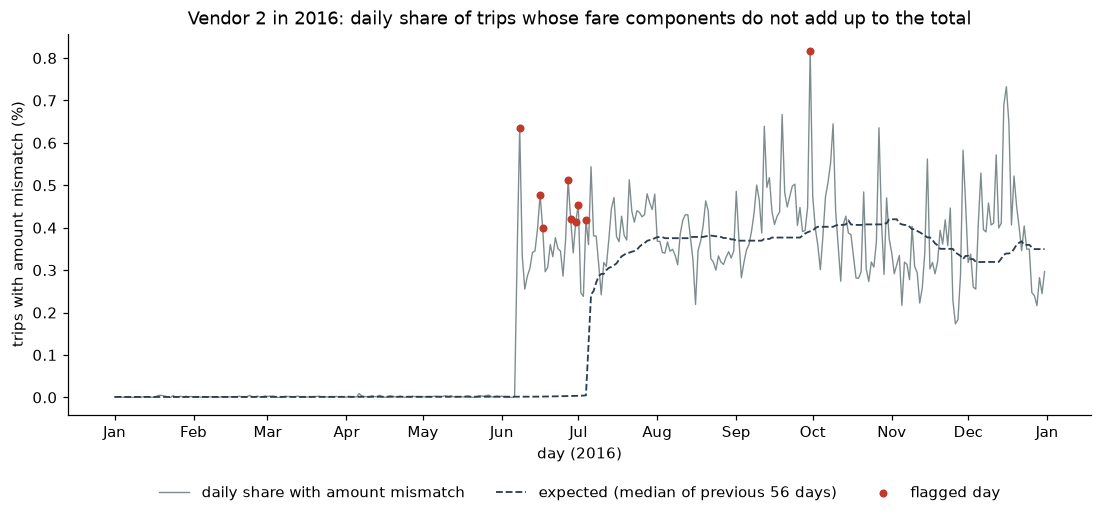

In [33]:
vendor2_2016 = vendor_daily[(vendor_daily["vendor"] == 2) & (vendor_daily["flag"] == "is_amount_mismatch")
                            & (vendor_daily["day"] >= "2016-01-01")]
flagged_days = vendor2_2016[vendor2_2016["flagged"]]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(vendor2_2016["day"], vendor2_2016["rate"], color="#7f8c8d", linewidth=0.9,
        label="daily share with amount mismatch")
ax.plot(vendor2_2016["day"], vendor2_2016["baseline"], color="#2c3e50", linewidth=1.2, linestyle="--",
        label="expected (median of previous 56 days)")
ax.scatter(flagged_days["day"], flagged_days["rate"], color=ANOMALY_COLOR, s=18, zorder=3, label="flagged day")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("Vendor 2 in 2016: daily share of trips whose fare components do not add up to the total")
ax.set_xlabel("day (2016)")
ax.set_ylabel("trips with amount mismatch (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
fig.savefig(FIG_DIR / "08_vendor2_amount_mismatch_2016.png", bbox_inches="tight")
plt.show()

The chart shows, for this series, the lag I wrote down as a possibility in 8.1. At Vendor 2 the rate is close to zero until the start of June 2016; at the start of June it jumps to about 0.6% and fluctuates between 0.2% and 0.7% for the rest of the year. The expected value, the median of the last 56 days, catches up with the new level only at the start of July. A window's median changes when more than half of the days in the window are at the new level; with a 56-day window this takes about four weeks. Most of the flagged days fall within these four weeks.

The chart also shows a limitation. All days in June are far above the expected value, but only some are flagged. Since I set the bound at 1% of each series' fit-window days, only a few days can be flagged in a series' fit window. The June change fell in the last weeks of the fit window, so these high days also pushed the bound itself up. Instead of flagging a long-lasting change day by day, a change-point method that finds the day the change starts would suit this case better.

The highest point, at the end of September, is flagged too. Even after the expected value caught up with the new level, that day's rate is clearly high.

### 8.4 What the time-based methods show

- About two thirds of the hours flagged city-wide fall on the event list I wrote without seeing the results. The most extreme hours not in the list are hours of holiday nights and of days after holidays. Anomalies in demand are mostly sudden drops.
- The window length barely changes the result. The real-time method flags more hours in the holdout than the retrospective method; one reason may be that it looks only at the past and adapts late to a change in demand.
- About half of the zone-level flags are in hours that are normal city-wide. These local flags are not scattered at random: they last a few hours or affect several zones together. Some of the longest local events match known events, such as New Year's Eve in Times Square and the Midtown closures during the Pope's visit; understanding the cause of the rest needs external data.
- Daily error rates by vendor find system events that are not visible in single records: outages on two separate days at Vendor 1 and Vendor 2's permanent change in June 2016.
- The real-time method cannot see an error that normally never occurs, or an event in the first days of monitoring. The fare-recording error of 1–4 January 2015 escaped the method for this reason.
- The difference that looked like a drop between the two periods in 4.1 came from two separate events at two separate vendors. Period averages can hide events over time; comparing two periods at a low time resolution can be misleading.

## 9. Comparing the methods

### 9.1 Do the methods flag the same trips?

Between Sections 4 and 7 I put nine different flags on trips: Task 2's rule flags; distance, duration, speed ratio and fare excess with group-based univariate bounds; tip; rare pickup–dropoff pair; and the multivariate physical and economic pairs. I left the rare passenger-count flag out of the comparison; it flags only 971 trips, so it says nothing meaningful in an overlap table.

The flags are defined on different groups of trips. The tip flag exists only on card trips with a tip, the economic pair only on standard-rate trips, the physical pair only on trips with distance above 0. In the comparison I counted a trip on which a flag is not defined as unflagged, so the denominator of the overlap tables is all trips. I computed the overlap on the fit window, because all bounds were set there.

I showed the overlap with two measures. Conditional overlap says what percentage of the trips flagged by one method another method also flags; for example, what percentage of the trips flagged by the distance bound the physical pair also flags. This measure differs in the two directions, because the methods flag different numbers of trips. Lift is the ratio of the number of trips two methods flag together to the number expected if they flagged unaware of each other. A lift near 1 means the two methods find independent things; a lift far above 1 means they find the same trips.

I recomputed all flags in a single scan. To check that the computation is right, I compared each flag's fit-window rate with the rate found in the flag's own section. If the difference exceeds 0.001 points, the cell stops.

In [34]:
from itertools import combinations


def guarded_univariate(column):
    """Section 6 per-segment flag, evaluated only where the column is defined."""
    _, condition = UNIVARIATE_COLUMNS[column]
    return f"(CASE WHEN {condition} THEN {univariate_flag_sql(column)} ELSE false END)"


_, tip_median, _, tip_mad = univariate_stats["tip_rate"]
tip_flag = (f"(CASE WHEN tip_rate > 0 THEN abs(ln(tip_rate) - {sql_number(tip_median)}) "
            f"/ {sql_number(1.4826 * tip_mad)} > {sql_number(RULES['univariate_mad_k']['tip_rate'])} ELSE false END)")

FLAG_DEFINITIONS = {
    "rule": (f"({any_rule_flag})", "true"),
    "distance": (guarded_univariate("trip_distance"), UNIVARIATE_COLUMNS["trip_distance"][1]),
    "duration": (guarded_univariate("duration_min"), UNIVARIATE_COLUMNS["duration_min"][1]),
    "speed_ratio": (guarded_univariate("speed_ratio"), UNIVARIATE_COLUMNS["speed_ratio"][1]),
    "fare_excess": (guarded_univariate("fare_excess"), UNIVARIATE_COLUMNS["fare_excess"][1]),
    "tip": (tip_flag, "tip_rate > 0"),
    "rare_od_pair": (f"COALESCE(od_pair_trips < {RULES['rare_od_pair_max_trips']}, false)", "od_pair_trips IS NOT NULL"),
    "physical": ("physical_flag", PAIR_COLUMNS["physical"][2]),
    "economic": ("economic_flag", PAIR_COLUMNS["economic"][2]),
}
STATISTICAL_FLAGS = [name for name in FLAG_DEFINITIONS if name != "rule"]

In [35]:
def with_pair_flag(source, pair):
    """Adds <pair>_flag: the trip is beyond its group's Mahalanobis bound from Section 7."""
    x1, x2, condition, group_sql = PAIR_COLUMNS[pair]
    inner = (f"SELECT *, CASE WHEN {condition} THEN {x1} END AS x1, CASE WHEN {condition} THEN {x2} END AS x2, "
             f"{group_sql} AS pair_group FROM ({source})")
    bound = group_case("pair_group", pair_ks[pair])
    return (f"SELECT * EXCLUDE (x1, x2, pair_group), "
            f"COALESCE({mahalanobis_sql(pair_fits[pair])} > {bound}, false) AS {pair}_flag FROM ({inner})")


def hourly_flag_counts(day_filter="TRUE"):
    """One scan: per pickup hour, trips, flag counts, eligible counts, pairwise overlaps, methods per trip."""
    source = f"SELECT *, {SEGMENT_GROUP} AS segment FROM matrix WHERE {day_filter}"
    source = with_pair_flag(with_pair_flag(source, "physical"), "economic")
    columns = ", ".join(f"{flag} AS f_{name}, {eligible} AS e_{name}"
                        for name, (flag, eligible) in FLAG_DEFINITIONS.items())
    flagged = f"SELECT tpep_pickup_datetime, in_fit_window, {columns} FROM ({source})"

    methods = " + ".join(f"CAST(f_{name} AS INTEGER)" for name in STATISTICAL_FLAGS)
    sums = [f"SUM(CAST(f_{name} AS INTEGER)) AS n_{name}, SUM(CAST(e_{name} AS INTEGER)) AS e_{name}"
            for name in FLAG_DEFINITIONS]
    sums += [f"SUM(CAST(f_{a} AND f_{b} AS INTEGER)) AS n_{a}__{b}" for a, b in combinations(FLAG_DEFINITIONS, 2)]
    sums += [f"SUM(CAST(({methods}) = {m} AS INTEGER)) AS methods_{m}" for m in (0, 1, 2)]
    sums += [f"SUM(CAST(({methods}) >= 3 AS INTEGER)) AS methods_3plus"]
    return con.execute(f"""
        SELECT date_trunc('hour', tpep_pickup_datetime) AS hour_start, bool_and(in_fit_window) AS in_fit,
               COUNT(*) AS trips, {', '.join(sums)}
        FROM ({flagged}) GROUP BY 1 ORDER BY 1
    """).df().set_index("hour_start")

In [36]:
hourly_flags = hourly_flag_counts()
fit_totals = hourly_flags[hourly_flags["in_fit"]].sum(numeric_only=True)


def fit_pct_over_groups(pair):
    """Fit-window flagged share of a Section 7 pair, weighted over its groups."""
    groups = mahalanobis_results.loc[pair]
    return (groups["fit_pct"] * groups["fit_trips"]).sum() / groups["fit_trips"].sum()


own_section_pct = {
    "rule": flag_rates.loc["any_rule_flag", "fit"],
    "distance": segment_comparison.loc["trip_distance", "fit_pct"],
    "duration": segment_comparison.loc["duration_min", "fit_pct"],
    "speed_ratio": segment_comparison.loc["speed_ratio", "fit_pct"],
    "fare_excess": segment_comparison.loc["fare_excess", "fit_pct"],
    "tip": tip_shares[0],
    "rare_od_pair": rare_pairs.loc["fit_pct", "value"],
    "physical": fit_pct_over_groups("physical"),
    "economic": fit_pct_over_groups("economic"),
}

flag_validation = pd.DataFrame({
    "flagged_fit": [fit_totals[f"n_{name}"] for name in FLAG_DEFINITIONS],
    "eligible_fit": [fit_totals[f"e_{name}"] for name in FLAG_DEFINITIONS],
}, index=list(FLAG_DEFINITIONS))
flag_validation["pct_here"] = 100 * flag_validation["flagged_fit"] / flag_validation["eligible_fit"]
flag_validation["pct_in_own_section"] = pd.Series(own_section_pct)
flag_validation["difference"] = flag_validation["pct_here"] - flag_validation["pct_in_own_section"]
assert flag_validation["difference"].abs().max() < 0.001, "A flag does not reproduce its own section"

flag_validation.round(4)

,flagged_fit,eligible_fit,pct_here,pct_in_own_section,difference
rule,3888932.0,215335294.0,1.8060,1.8060,0.0
distance,1670365.0,213901220.0,0.7809,0.7809,0.0
duration,2096663.0,214824950.0,0.9760,0.9760,0.0
speed_ratio,2105415.0,210541432.0,1.0000,1.0000,0.0
fare_excess,2085660.0,208750781.0,0.9991,0.9991,0.0
tip,1266349.0,131874340.0,0.9603,0.9603,0.0
rare_od_pair,496944.0,211727216.0,0.2347,0.2347,-0.0
physical,2136153.0,213634422.0,0.9999,0.9999,0.0
economic,2055029.0,205502713.0,1.0000,1.0000,0.0


In [37]:
FLAG_NAMES = list(FLAG_DEFINITIONS)


def overlap_count(a, b):
    """Fit-window trips flagged by both a and b."""
    if a == b:
        return fit_totals[f"n_{a}"]
    key = f"n_{a}__{b}"
    return fit_totals[key] if key in fit_totals else fit_totals[f"n_{b}__{a}"]


conditional_overlap = pd.DataFrame(
    [[100 * overlap_count(a, b) / fit_totals[f"n_{a}"] for b in FLAG_NAMES] for a in FLAG_NAMES],
    index=pd.Index(FLAG_NAMES, name="% of row's flags also flagged by column"),
    columns=FLAG_NAMES,
)
conditional_overlap.round(1)

,rule,distance,duration,speed_ratio,fare_excess,tip,rare_od_pair,physical,economic
% of row's flags also flagged by column,,,,,,,,,
rule,100.0,8.1,28.9,2.8,0.5,4.8,0.3,13.3,0.7
distance,18.9,100.0,25.9,21.6,2.3,2.2,9.9,55.3,6.4
duration,53.6,20.6,100.0,6.3,2.4,2.4,0.4,37.2,3.4
speed_ratio,5.2,17.2,6.2,100.0,8.9,1.0,0.7,49.5,11.5
fare_excess,0.9,1.9,2.4,9.0,100.0,2.6,0.6,9.6,89.2
tip,14.7,2.8,3.9,1.7,4.3,100.0,1.0,2.2,4.3
rare_od_pair,2.3,33.2,1.8,2.9,2.5,2.4,100.0,14.4,2.9
physical,24.3,43.2,36.5,48.8,9.4,1.3,3.3,100.0,12.2
economic,1.3,5.2,3.5,11.8,90.6,2.6,0.7,12.7,100.0


The first column of the table answers the question I asked in 4.2: how many of the trips flagged by the statistical methods had Task 2's rules already flagged? This share varies a lot by method. 53.6% of the trips flagged on duration, 24.3% in the physical pair and 18.9% on distance also hit the rules. For the speed ratio this share is 5.2%, for the rare pair 2.3%, for the economic pair 1.3% and for fare excess only 0.9%. Duration rediscovers part of the errors Task 2 knows. The speed ratio, fare excess and the economic pair find almost only trips the rules do not see.

From the other direction, the statistical methods do not see most of the trips caught by the rules. Duration flags 28.9% of the rule-flagged trips, the physical pair 13.3% and distance 8.1%; the other methods' shares are below 5%. The rules and the statistical methods largely catch different trips.

Two methods find almost the same thing: fare excess and the economic pair. The economic pair also flags 89.2% of the trips flagged by fare excess, and fare excess flags 90.6% of those flagged by the economic pair. The economic pair's flags come mostly from the fare side; the speed ratio adds little to this pair. The physical pair overlaps with three univariate methods at once: 43.2% of the trips it flags are also flagged on distance, 36.5% on duration and 48.8% on the speed ratio. This is expected, because speed is the ratio of distance to duration.

In 6.2 I asked whether rare pairs are also flagged by other methods. 33.2% of rare pairs are also outside the distance bound; the overlap with the other methods is below 15%. A rare pair is often just a long distance; the remaining methods see nothing unusual in these trips. The tip flag also overlaps very little with the other statistical methods (at most 4.3%); it carries information independent of the trip's other properties.

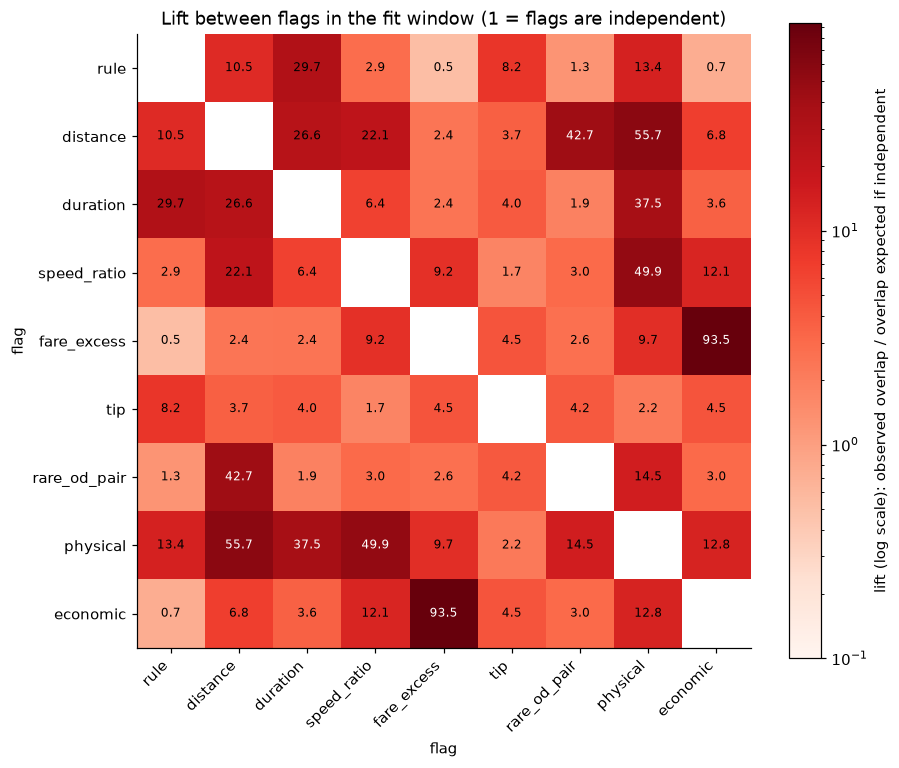

In [38]:
from matplotlib.colors import LogNorm

fit_trip_count = fit_totals["trips"]
lift = pd.DataFrame(
    [[np.nan if a == b else overlap_count(a, b) * fit_trip_count / (fit_totals[f"n_{a}"] * fit_totals[f"n_{b}"])
      for b in FLAG_NAMES] for a in FLAG_NAMES],
    index=FLAG_NAMES, columns=FLAG_NAMES,
)

fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(lift, cmap="Reds", norm=LogNorm(vmin=0.1, vmax=np.nanmax(lift.to_numpy())))
for i, a in enumerate(FLAG_NAMES):
    for j, b in enumerate(FLAG_NAMES):
        if a != b:
            ax.text(j, i, f"{lift.loc[a, b]:.1f}", ha="center", va="center", fontsize=8,
                    color="white" if lift.loc[a, b] > 30 else "black")
ax.set_xticks(range(len(FLAG_NAMES)), FLAG_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(FLAG_NAMES)), FLAG_NAMES)
fig.colorbar(image, ax=ax, label="lift (log scale): observed overlap / overlap expected if independent")
ax.set_title("Lift between flags in the fit window (1 = flags are independent)")
ax.set_xlabel("flag")
ax.set_ylabel("flag")
fig.savefig(FIG_DIR / "09_flag_lift.png", bbox_inches="tight")
plt.show()

Almost all lift values are above 1. Although the methods work with different bounds and different columns, the trips they flag are not distributed at random: a trip that is unusual in one respect tends to be unusual in another too. Even between the most distant methods the lift is mostly between 2 and 4.

The highest values are between methods that use the same information. The lift between fare excess and the economic pair is 93.5; as in the conditional overlap table, these two flags find almost the same trips. The physical pair shows high lift with distance (55.7), speed ratio (49.9) and duration (37.5), because these three columns are either components of the physical pair or derived from them. The lift between the rare pair and distance is 42.7.

Two values are below 1: 0.5 between the rules and fare excess, and 0.7 between the rules and the economic pair. Trips caught by the rules do not tend to be extreme on the fare side; they are less extreme than they would be if independent. Part of this may come from the measurement itself. Fare excess is defined only on standard-rate trips, while some of the rules flag errors in the rate code or the fare record. A trip whose fare excess cannot be computed cannot get a fare flag either.

The tip shows low lift with all methods (between 1.7 and 8.2). Together with the conditional overlap table, the tip is the flag most independent of the other methods.

In [39]:

holdout_days = (pd.Timestamp("2017-01-01") - pd.Timestamp(FIT_END)).days
holdout_totals = hourly_flags[~hourly_flags["in_fit"]].sum(numeric_only=True)

alarm_rows = {}
for period, totals, n_days in [("fit", fit_totals, fit_days), ("holdout", holdout_totals, holdout_days)]:
    trips = totals["trips"]
    flagged_any = trips - totals["methods_0"]
    alarm_rows[period] = {
        "trips": trips,
        "flagged by 0 statistical methods (%)": 100 * totals["methods_0"] / trips,
        "flagged by 1 method (%)": 100 * totals["methods_1"] / trips,
        "flagged by 2 methods (%)": 100 * totals["methods_2"] / trips,
        "flagged by 3 or more methods (%)": 100 * totals["methods_3plus"] / trips,
        "trips flagged by at least one method, per day": flagged_any / n_days,
        "trips flagged by 2 or more methods, per day": (totals["methods_2"] + totals["methods_3plus"]) / n_days,
        "trips flagged by 3 or more methods, per day": totals["methods_3plus"] / n_days,
        "trips with a Task 2 rule flag, per day": totals["n_rule"] / n_days,
    }

pd.DataFrame(alarm_rows).apply(
    lambda row: row.map("{:.3f}".format) if "(%)" in row.name else row.map("{:,.0f}".format),
    axis=1,
)

,fit,holdout
trips,"215,335,294","61,727,020"
flagged by 0 statistical methods (%),96.048,95.284
flagged by 1 method (%),2.111,2.306
flagged by 2 methods (%),1.336,1.792
flagged by 3 or more methods (%),0.506,0.618
"trips flagged by at least one method, per day","15,557","15,821"
"trips flagged by 2 or more methods, per day","7,248","8,084"
"trips flagged by 3 or more methods, per day","1,990","2,073"
"trips with a Task 2 rule flag, per day","7,110","5,830"


Together, the eight statistical methods leave 96.048% of fit-window trips untouched. The remaining roughly 4% are flagged by at least one method; that is 15,557 trips a day on average. In 5.1 I saw that a single variable flags about 3,900 trips a day. Used together, the methods raise this number fourfold. An audit team cannot review that many trips every day.

About half of the flagged trips are flagged by more than one method. Trips flagged by two or more methods amount to 7,248 a day, those flagged by three or more to 1,990 a day. Several methods meeting on the same trip is stronger evidence that the trip is truly unusual. The number of methods is therefore a natural measure for prioritising alarms. Starting from trips flagged by three or more methods cuts the number of alarms to review to below a quarter. That is still about 2,000 trips a day, more than a single team can review.

The flagged share is higher in the holdout: trips flagged by at least one method are about 4% in the fit window and about 4.7% in the holdout. The 2016 shift seen in Sections 5 and 7 shows up here too. Task 2's rule flags change in the opposite direction: from 7,110 a day to 5,830.

These numbers show that the statistical methods are not enough on their own as an alarm system. The methods find what is unusual, but they cannot rank which of these trips is worth reviewing. That needs a method that ranks trips with a single score. I discussed this in Section 11 together with what I expect from ML methods.

### 9.2 Comparison at the time level

In 8.1 I used two methods for hourly demand: the retrospective decomposition that analyses the past and the real-time method that looks only at the past. How far the two methods flag the same hours shows how many of the events found by retrospective analysis could be caught at the time, with a real-time alarm.

I also looked for a link between anomalies at the time level and at the trip level: in hours when demand is unusual, does the share of flagged trips rise too? I measured this with two separate rates: the share of trips flagged by at least one statistical method and the share of trips carrying Task 2's rule flags. I weighted the hours by their number of trips, so that hours with very few trips, such as during the blizzard, do not decide the result on their own. On the fall-back nights the duration computation produces wrong flags mechanically, so I reported the result with and without the DST hours.

In [40]:
retrospective_flag = hourly_methods["decomposition"].abs() > hourly_k["decomposition"]

time_overlap = {}
for period, in_period in [("fit", in_fit_hour), ("holdout", ~in_fit_hour)]:
    retro, realtime = retrospective_flag[in_period], realtime_flagged[in_period]
    time_overlap[period] = {
        "hours": int(in_period.sum()),
        "flagged by both methods": int((retro & realtime).sum()),
        "flagged only by the retrospective method": int((retro & ~realtime).sum()),
        "flagged only by the real-time method": int((realtime & ~retro).sum()),
        "retrospective flags also caught in real time (%)": 100 * (retro & realtime).sum() / retro.sum(),
    }

pd.DataFrame(time_overlap).apply(
    lambda row: row.map("{:.3f}".format) if "(%)" in row.name else row.map("{:,.0f}".format),
    axis=1,
)

,fit,holdout
hours,"13,128","4,416"
flagged by both methods,90,29
flagged only by the retrospective method,42,4
flagged only by the real-time method,35,26
retrospective flags also caught in real time (%),68.182,87.879


In [41]:
aligned = hourly_flags.reindex(log_trips.index)
statistically_flagged = aligned["trips"] - aligned["methods_0"]
anomalous_hour = realtime_flagged.to_numpy()

bridge_rows = {}
for label, base in [("all fit hours", in_fit_hour),
                    ("fit hours without DST nights", in_fit_hour & ~event_hours["dst"].to_numpy())]:
    for state, in_state in [("anomalous hours", base & anomalous_hour), ("normal hours", base & ~anomalous_hour)]:
        trips = aligned.loc[in_state, "trips"].sum()
        bridge_rows[(label, state)] = {
            "hours": f"{int(in_state.sum()):,}",
            "trips": f"{int(trips):,}",
            "statistically flagged (%)": f"{100 * statistically_flagged[in_state].sum() / trips:.3f}",
            "rule flagged (%)": f"{100 * aligned.loc[in_state, 'n_rule'].sum() / trips:.3f}",
        }

pd.DataFrame(bridge_rows).T

hours        trips  \
all fit hours                anomalous hours     125      739,004   
                             normal hours     13,003  214,596,290   
fit hours without DST nights anomalous hours     122      692,981   
                             normal hours     13,000  214,530,494   

                                             statistically flagged (%)  \
all fit hours                anomalous hours                     5.986   
                             normal hours                        3.945   
fit hours without DST nights anomalous hours                     5.993   
                             normal hours                        3.941   

                                             rule flagged (%)  
all fit hours                anomalous hours            2.665  
                             normal hours               1.803  
fit hours without DST nights anomalous hours            1.897  
                             normal hours               1.803

The two time methods largely flag the same hours. In the fit window the real-time method also flags 90 of the 132 hours flagged by the retrospective method (68.182%); in the holdout this rate is 87.879%. Most events found by retrospective analysis could also have been caught by an alarm running at the time. The remaining hours can be seen only by looking back. Hours flagged only by the real-time method are relatively more frequent in the holdout (35 in the fit window, 26 in the holdout); this matches the holdout difference I saw in 8.1.

In hours when demand is unusual, trips are also flagged more often. In the 125 hours the real-time method finds anomalous, 5.986% of trips are flagged by at least one statistical method; in normal hours this rate is 3.945%. The rate of rule flags rises too: 2.665% versus 1.803%.

Removing the DST nights changes the picture. The difference in statistical flags stays the same (5.993% versus 3.941%), but the difference in rule flags almost disappears (1.897% versus 1.803%). The rise in rule flags came mostly from the duration error on the DST nights. The rise in statistical flags is independent of DST: when demand is unusual, the distance, duration, speed or fare of the trips in those hours is more likely to be unusual too.

### 9.3 What the comparison shows

- Task 2's rules and the statistical methods largely catch different trips. The method that overlaps most with the rules is duration: more than half of what it flags already hits the rules. The speed ratio, fare excess and the economic pair find almost only trips the rules do not see.
- Fare excess and the economic pair flag almost the same trips; the economic pair adds little to fare excess. The tip is the flag most independent of all other methods.
- Flags tend to gather on the same trips: a trip that is unusual in one respect can be unusual in another too. Trips flagged by more than one method are a natural starting point for prioritising review.
- Together the eight statistical methods flag about 15,600 trips a day. Even limited to trips flagged by three or more methods, about 2,000 trips a day remain. The statistical methods find what is unusual, but cannot rank which should be reviewed first.
- The real-time method also catches, at the time, most of the anomalous hours found by retrospective analysis: about two thirds in the fit window and about 88% in the holdout.
- In hours when demand is unusual, trips are also flagged statistically more often. The rise in rule flags comes mostly from the duration error on the DST nights.

## 10. Manual inspection of anomaly examples

There is no label in this data saying which trip is truly anomalous. To see how many of the trips the methods flag are a real problem and how many are rare but legitimate trips, I looked at the records one by one.

I picked nine trips from each of the eight statistical methods, 72 in total. I took the nine trips three each from three bands: the trips farthest from the bound, those in the middle of the flagged trips, and those just above the bound. Looking only at the most extreme trips would make the methods look better than they are, because the most extreme records are usually obvious errors; the real uncertainty is near the bound. Since the methods' scores are on different scales, I divided each trip's score by its own bound; 1 means right at the bound. I picked the trips from the fit window with a hash of their key columns, so the same trips come up in every run. I matched each trip with the raw data and also showed the dropoff time, raw distance, fare components, rate code and payment type.

I assigned the labels with explicit criteria for the four labels in 3.4, written before looking at any record. Each record is checked in order and the first matching label is given:
- Explained anomaly: the trip is inside an event from 3.3 and the event explains the flag. Trips spanning 02:00 on a spring-forward night, pickups between 01:00 and 02:00 on a fall-back night, and blizzard days.
- Real error: one of Task 2's validity flags is set, or the raw record is physically impossible. The speed computed from the raw distance and duration is above 80 mph, or the duration is zero or negative.
- Legitimate but rare: speed between 2 and 50 mph, distance above zero and duration between 1 minute and 4 hours.
- Unclear: all other records.

The thresholds come from Task 2's rules; the only new threshold is 2 mph, below walking speed. I did not change any label by personal judgement; this keeps the labelling reproducible, and the reason for each label is explicit in these criteria. The records are shown below method by method. The criteria have one limitation: they do not evaluate the fare. A trip flagged on fare excess but with a normal speed gets the "legitimate but rare" label; these criteria cannot decide whether the fare is truly unexplainable. Nine records per method is a small sample; the rates that come out of it are not precise values but show the direction of the differences between methods.

In [42]:
VALIDITY_FLAGS = ["is_distance_invalid", "is_duration_invalid", "is_amount_mismatch",
                  "is_fare_below_minimum", "is_ratecode_invalid"]
TRIP_KEY = ["tpep_pickup_datetime", "PULocationID", "DOLocationID", "VendorID", "total_amount"]
RAW_FIELDS = ["tpep_dropoff_datetime", "trip_distance AS raw_distance", "fare_amount AS raw_fare", "extra",
              "tolls_amount", "tip_amount", "payment_type", "RatecodeID"]


def rubric_label(trips):
    """Section 10 rubric: explained, error, legitimate but rare, unclear (first match wins)."""
    pickup, dropoff = trips["tpep_pickup_datetime"], trips["tpep_dropoff_datetime"]
    day, hour = pickup.dt.normalize(), pickup.dt.hour
    duration_s = (dropoff - pickup).dt.total_seconds()
    speed_mph = trips["raw_distance"] / (duration_s / 3600)

    spring_forward = (day.isin(pd.to_datetime(["2015-03-08", "2016-03-13"])) & (hour < 2)
                      & (dropoff >= day + pd.Timedelta(hours=3)))
    fall_back = day.isin(pd.to_datetime(["2015-11-01", "2016-11-06"])) & (hour == 1)
    blizzard = day.isin(pd.to_datetime(["2016-01-23", "2016-01-24"]))
    explained = spring_forward | fall_back | blizzard
    error = (trips[VALIDITY_FLAGS].fillna(False).astype(bool).any(axis=1)
             | (speed_mph > TASK2_RULES["max_speed_mph"]) | (duration_s <= 0))
    legitimate = (speed_mph.between(2, TASK2_RULES["high_speed_mph"]) & (trips["raw_distance"] > 0)
                  & duration_s.between(TASK2_RULES["very_short_s"], TASK2_RULES["max_duration_s"]))
    return pd.Series(np.select([explained, error, legitimate],
                               ["explained", "error", "legitimate but rare"], default="unclear"),
                     index=trips.index)

In [43]:
def univariate_ratio_sql(column):
    """Section 6 score divided by its segment bound; above 1 means flagged."""
    expression, condition = UNIVARIATE_COLUMNS[column]
    stats = segment_stats[column]
    return (f"(CASE WHEN {condition} THEN abs(({expression}) - {segment_case(stats['median'])}) "
            f"/ {segment_case(1.4826 * stats['mad'])} / {segment_case(stats['k'])} END)")


def with_pair_ratio(source, pair):
    """Adds <pair>_ratio: Section 7 squared distance divided by its group bound."""
    x1, x2, condition, group_sql = PAIR_COLUMNS[pair]
    inner = (f"SELECT *, CASE WHEN {condition} THEN {x1} END AS x1, CASE WHEN {condition} THEN {x2} END AS x2, "
             f"{group_sql} AS pair_group FROM ({source})")
    bound = group_case("pair_group", pair_ks[pair])
    return f"SELECT * EXCLUDE (x1, x2, pair_group), {mahalanobis_sql(pair_fits[pair])} / {bound} AS {pair}_ratio FROM ({inner})"


SCORE_RATIOS = {
    "distance": univariate_ratio_sql("trip_distance"),
    "duration": univariate_ratio_sql("duration_min"),
    "speed_ratio": univariate_ratio_sql("speed_ratio"),
    "fare_excess": univariate_ratio_sql("fare_excess"),
    "tip": (f"(CASE WHEN tip_rate > 0 THEN abs(ln(tip_rate) - {sql_number(tip_median)}) / "
            f"{sql_number(1.4826 * tip_mad)} / {sql_number(RULES['univariate_mad_k']['tip_rate'])} END)"),
    "rare_od_pair": f"({RULES['rare_od_pair_max_trips']} / od_pair_trips)",
    "physical": "physical_ratio",
    "economic": "economic_ratio",
}


def sample_bands(method, per_band=3, candidates=5):
    """Fit-window trips flagged by one method: flagged count and candidates from three bands."""
    source = f"SELECT *, {SEGMENT_GROUP} AS segment FROM matrix WHERE in_fit_window"
    source = with_pair_ratio(with_pair_ratio(source, "physical"), "economic")
    con.execute(f"""
        CREATE OR REPLACE TEMP TABLE flagged_trips AS
        SELECT {', '.join(TRIP_KEY)}, {', '.join(VALIDITY_FLAGS)}, {SCORE_RATIOS[method]} AS ratio,
               hash({', '.join(TRIP_KEY)}) AS trip_hash
        FROM ({source}) WHERE {SCORE_RATIOS[method]} > 1
    """)
    flagged = con.execute("SELECT COUNT(*) FROM flagged_trips").fetchone()[0]
    bands = con.execute(f"""
        WITH ranked AS (SELECT *, percent_rank() OVER (ORDER BY ratio) AS rank FROM flagged_trips)
        (SELECT *, 'farthest' AS band FROM ranked ORDER BY ratio DESC, trip_hash LIMIT {candidates})
        UNION ALL
        (SELECT *, 'middle' AS band FROM ranked WHERE rank BETWEEN 0.45 AND 0.55 ORDER BY trip_hash LIMIT {candidates})
        UNION ALL
        (SELECT *, 'at the bound' AS band FROM ranked ORDER BY ratio, trip_hash LIMIT {candidates})
    """).df()
    return flagged, bands.assign(method=method)

In [44]:
candidate_frames = []
for method in STATISTICAL_FLAGS:
    flagged, bands = sample_bands(method)
    assert flagged == fit_totals[f"n_{method}"], f"{method}: flagged trips differ from Section 9"
    candidate_frames.append(bands.assign(candidate_order=range(len(bands))))

candidates = pd.concat(candidate_frames, ignore_index=True)
con.register("inspection_candidates", candidates)
raw_matched = con.execute(f"""
    SELECT c.*, {', '.join('r.' + field for field in RAW_FIELDS)},
           COUNT(r.tpep_dropoff_datetime) OVER (PARTITION BY c.method, c.band, c.candidate_order) AS raw_matches
    FROM inspection_candidates AS c
    LEFT JOIN raw_trips AS r USING ({', '.join(TRIP_KEY)})
""").df()

inspection = (raw_matched[raw_matched["raw_matches"] == 1]
              .sort_values(["method", "band", "candidate_order"])
              .groupby(["method", "band"]).head(3)
              .reset_index(drop=True))
inspection["proposed_label"] = rubric_label(inspection)
assert inspection.groupby("method").size().eq(9).all(), "A method has fewer than 9 inspected trips"

pd.crosstab([inspection["method"], inspection["band"]], inspection["proposed_label"])

proposed_label             error  explained  legitimate but rare  unclear
method       band                                                        
distance     at the bound      1          0                    1        1
             farthest          0          0                    0        3
             middle            0          0                    3        0
duration     at the bound      0          1                    2        0
             farthest          2          0                    0        1
             middle            0          0                    0        3
economic     at the bound      0          0                    3        0
             farthest          0          0                    2        1
             middle            0          0                    3        0
fare_excess  at the bound      0          0                    3        0
             farthest          3          0                    0        0
             middle            0          0                    3        0
physical     at the bound      0          0                    3        0
             farthest          0          0                    0        3
             middle            0          0                    2        1
rare_od_pair at the bound      0          0                    3        0
             farthest          0          0                    3        0
             middle            0          0                    3        0
speed_ratio  at the bound      0          0                    3        0
             farthest          0          0                    0        3
             middle            0          0                    3        0
tip          at the bound      0          0                    3        0
             farthest          0          0                    3        0
             middle            0          0                    3        0

In [45]:
zones = pd.read_csv(ZONE_LOOKUP).set_index("LocationID")["Zone"]
BAND_ORDER = {"farthest": 0, "middle": 1, "at the bound": 2}


def inspection_table(method):
    """Nine inspected trips of one method with raw fields and the proposed label."""
    trips = (inspection[inspection["method"] == method]
             .sort_values("band", key=lambda band: band.map(BAND_ORDER)).copy())
    minutes = (trips["tpep_dropoff_datetime"] - trips["tpep_pickup_datetime"]).dt.total_seconds() / 60
    table = pd.DataFrame({
        "band": trips["band"],
        "score / bound": trips["ratio"].round(2),
        "pickup": trips["tpep_pickup_datetime"].dt.strftime("%Y-%m-%d %H:%M"),
        "from": trips["PULocationID"].map(zones),
        "to": trips["DOLocationID"].map(zones),
        "miles": trips["raw_distance"],
        "minutes": minutes.round(1),
        "mph": (trips["raw_distance"] / (minutes / 60)).round(1),
        "rate code": trips["RatecodeID"],
        "fare": trips["raw_fare"],
        "extra": trips["extra"],
        "tolls": trips["tolls_amount"],
        "tip": trips["tip_amount"],
        "total": trips["total_amount"],
        "payment": trips["payment_type"],
        "proposed label": trips["proposed_label"],
    })
    table.index = [f"{method}-{i}" for i in range(1, len(table) + 1)]
    return table

In [46]:
inspection_table("distance")

,band,score / bound,pickup,from,to,miles,minutes,mph,rate code,fare,extra,tolls,tip,total,payment,proposed label
distance-1,farthest,4.10,2015-10-13 05:37,LaGuardia Airport,LaGuardia Airport,0.01,2.0,0.3,1,3.5,0.5,0.00,0.00,4.80,2,unclear
distance-2,farthest,4.10,2015-11-08 15:28,LaGuardia Airport,LaGuardia Airport,0.01,0.6,1.1,1,2.5,0.0,0.00,0.00,3.30,2,unclear
distance-3,farthest,4.10,2015-08-12 12:33,LaGuardia Airport,LaGuardia Airport,0.01,0.6,1.1,1,2.5,0.0,0.00,31.70,35.00,1,unclear
distance-4,middle,1.16,2015-12-08 08:44,UN/Turtle Bay South,East Harlem South,17.79,120.6,8.8,1,81.0,0.0,0.00,10.00,91.80,1,legitimate but rare
distance-5,middle,1.13,2016-03-05 12:26,Flatbush/Ditmas Park,East Elmhurst,16.74,56.9,17.7,1,54.5,0.0,0.00,0.00,55.30,2,legitimate but rare
distance-6,middle,1.12,2016-05-06 18:21,Sutton Place/Turtle Bay North,Kew Gardens Hills,16.55,36.3,27.3,1,46.0,1.0,5.54,10.67,64.01,1,legitimate but rare
distance-7,at the bound,1.00,2015-09-06 08:21,Baisley Park,Outside of NYC,66.70,74.8,53.5,5,0.0,0.0,5.54,0.00,5.84,3,error
distance-8,at the bound,1.00,2015-05-12 19:23,NaN,NaN,66.70,95.3,42.0,1,172.0,1.0,8.00,10.00,191.80,1,legitimate but rare
distance-9,at the bound,1.00,2015-02-15 10:12,UN/Turtle Bay South,Outside of NYC,66.70,72.6,55.1,5,200.0,0.0,0.00,0.00,200.30,1,unclear


In [47]:
inspection_table("duration")

,band,score / bound,pickup,from,to,miles,minutes,mph,rate code,fare,extra,tolls,tip,total,payment,proposed label
duration-1,farthest,4.93,2015-02-10 16:37,NaN,LaGuardia Airport,0.02,0.0,72.0,2,52.0,0.0,0.00,10.56,63.36,1,unclear
duration-2,farthest,4.93,2015-08-20 22:15,LaGuardia Airport,LaGuardia Airport,9.50,0.0,34200.0,1,2.5,0.5,0.00,0.00,3.80,3,error
duration-3,farthest,4.93,2016-02-21 21:48,LaGuardia Airport,LaGuardia Airport,1.40,0.0,5040.0,1,2.5,0.5,0.00,0.00,3.80,2,error
duration-4,middle,1.22,2015-05-23 05:57,Borough Park,Borough Park,0.00,1.0,0.0,1,2.5,0.5,0.00,0.00,3.80,2,unclear
duration-5,middle,1.24,2016-05-03 10:02,Midtown Center,Midtown North,0.10,0.9,6.4,1,3.0,0.0,0.00,0.00,3.80,2,unclear
duration-6,middle,1.21,2015-01-10 11:37,Upper East Side South,Upper East Side South,0.20,1.0,12.2,1,3.0,0.0,0.00,0.00,3.80,2,unclear
duration-7,at the bound,1.00,2015-06-11 11:48,East Village,LaGuardia Airport,15.30,123.5,7.4,1,45.0,0.0,5.54,10.26,61.60,1,legitimate but rare
duration-8,at the bound,1.00,2015-03-08 01:55,Union Sq,Clinton West,2.40,73.4,2.0,1,11.5,0.5,0.00,2.56,15.36,1,explained
duration-9,at the bound,1.00,2015-05-04 12:18,Baisley Park,Upper West Side North,17.50,73.4,14.3,2,52.0,0.0,5.54,0.00,58.34,2,legitimate but rare


In [48]:
inspection_table("speed_ratio")

,band,score / bound,pickup,from,to,miles,minutes,mph,rate code,fare,extra,tolls,tip,total,payment,proposed label
speed_ratio-1,farthest,7.39,2015-09-17 05:06,SoHo,Midtown East,0.01,131.0,0.0,2,52.0,0.0,0.00,10.50,63.00,1,unclear
speed_ratio-2,farthest,7.27,2015-06-01 10:56,Willets Point,Long Island City/Hunters Point,0.01,120.3,0.0,2,52.0,0.0,0.00,0.00,52.80,2,unclear
speed_ratio-3,farthest,7.23,2015-07-17 17:29,Midwood,Two Bridges/Seward Park,0.01,206.0,0.0,1,2.5,1.0,0.00,0.00,4.30,2,unclear
speed_ratio-4,middle,1.12,2016-06-03 10:40,Lower East Side,Bay Ridge,11.10,22.2,30.1,1,32.0,0.0,0.00,0.00,32.80,1,legitimate but rare
speed_ratio-5,middle,1.16,2015-05-19 15:12,Times Sq/Theatre District,Riverdale/North Riverdale/Fieldston,11.19,24.2,27.7,1,33.0,0.0,2.54,0.00,36.34,2,legitimate but rare
speed_ratio-6,middle,1.13,2015-09-24 16:29,West Chelsea/Hudson Yards,West Chelsea/Hudson Yards,9.04,17.7,30.7,1,26.5,1.0,5.54,8.46,42.30,1,legitimate but rare
speed_ratio-7,at the bound,1.00,2015-05-13 07:15,Midtown East,Midtown Center,0.65,12.4,3.1,1,8.5,0.0,0.00,2.79,12.09,1,legitimate but rare
speed_ratio-8,at the bound,1.00,2015-10-16 19:25,UN/Turtle Bay South,Penn Station/Madison Sq West,1.50,28.1,3.2,1,16.5,1.0,0.00,4.55,22.85,1,legitimate but rare
speed_ratio-9,at the bound,1.00,2015-02-06 10:03,Midtown North,Lincoln Square East,0.90,22.5,2.4,1,13.5,0.0,0.00,2.85,17.15,1,legitimate but rare


In [49]:
inspection_table("fare_excess")

,band,score / bound,pickup,from,to,miles,minutes,mph,rate code,fare,extra,tolls,tip,total,payment,proposed label
fare_excess-1,farthest,51.18,2015-12-17 06:20,Canarsie,East New York,1.61,0.0,inf,1,465.0,0.0,0.0,0.00,465.80,2,error
fare_excess-2,farthest,49.35,2015-08-15 00:58,Outside of NYC,Outside of NYC,1.33,940.0,0.1,1,473.0,0.5,0.0,0.00,474.30,2,error
fare_excess-3,farthest,41.87,2015-03-06 07:49,West Concourse,Hunts Point,5.89,0.0,inf,1,393.5,1.0,0.0,0.00,395.30,2,error
fare_excess-4,middle,1.18,2015-02-13 13:49,Midtown North,Williamsburg (South Side),6.80,46.3,8.8,1,33.0,0.0,0.0,6.75,40.55,1,legitimate but rare
fare_excess-5,middle,1.22,2016-04-05 13:21,Upper East Side North,Central Park,1.47,32.5,2.7,1,19.0,0.0,0.0,0.00,19.80,2,legitimate but rare
fare_excess-6,middle,1.20,2015-09-29 14:47,Morningside Heights,Lenox Hill East,4.90,44.6,6.6,1,28.0,0.0,0.0,0.00,28.80,1,legitimate but rare
fare_excess-7,at the bound,1.00,2015-04-11 18:14,JFK Airport,Park Slope,14.92,69.2,12.9,1,56.5,0.0,0.0,11.46,68.76,1,legitimate but rare
fare_excess-8,at the bound,1.00,2016-06-02 17:30,JFK Airport,Sunset Park West,14.92,71.3,12.6,1,56.5,1.0,0.0,0.00,58.30,2,legitimate but rare
fare_excess-9,at the bound,1.00,2015-10-27 06:30,JFK Airport,Williamsburg (North Side),14.92,76.4,11.7,1,56.5,0.0,0.0,14.32,71.62,1,legitimate but rare


In [50]:
inspection_table("tip")

,band,score / bound,pickup,from,to,miles,minutes,mph,rate code,fare,extra,tolls,tip,total,payment,proposed label
tip-1,farthest,5.67,2016-05-09 20:32,LaGuardia Airport,Outside of NYC,5.00,90.5,3.3,2,130.0,0.0,0.00,0.01,130.81,1,legitimate but rare
tip-2,farthest,5.61,2015-03-13 04:55,West Village,Jamaica,42.00,98.2,25.7,1,120.0,0.5,5.33,0.01,126.64,1,legitimate but rare
tip-3,farthest,5.56,2015-11-20 00:20,Sutton Place/Turtle Bay North,Charleston/Tottenville,39.40,81.2,29.1,1,111.5,0.5,36.12,0.01,148.93,1,legitimate but rare
tip-4,middle,1.17,2016-01-30 18:37,Meatpacking/West Village West,Lenox Hill West,4.79,34.5,8.3,1,23.5,0.0,0.00,1.00,25.30,1,legitimate but rare
tip-5,middle,1.14,2015-04-26 23:55,Bushwick North,Prospect-Lefferts Gardens,6.30,26.5,14.3,1,22.5,0.5,0.00,1.00,24.80,1,legitimate but rare
tip-6,middle,1.21,2015-04-26 08:48,Greenwich Village North,West Village,0.80,2.9,16.7,1,5.0,0.0,0.00,0.20,6.00,1,legitimate but rare
tip-7,at the bound,1.00,2016-02-27 12:35,East Village,Outside of NYC,5.60,27.2,12.4,1,22.0,0.0,12.50,19.70,55.00,1,legitimate but rare
tip-8,at the bound,1.00,2015-08-01 01:54,Central Harlem,Starrett City,31.41,52.4,35.9,1,84.0,0.5,5.54,4.54,95.38,1,legitimate but rare
tip-9,at the bound,1.00,2016-01-27 00:27,Chinatown,Bedford,4.09,19.0,12.9,1,15.5,0.5,0.00,13.88,30.68,1,legitimate but rare


In [51]:
inspection_table("rare_od_pair")

,band,score / bound,pickup,from,to,miles,minutes,mph,rate code,fare,extra,tolls,tip,total,payment,proposed label
rare_od_pair-1,farthest,100.00,2015-06-27 22:30,Howard Beach,Inwood Hill Park,27.66,69.4,23.9,1,78.0,0.5,0.00,0.00,79.30,2,legitimate but rare
rare_od_pair-2,farthest,100.00,2015-11-21 07:37,Douglaston,Lincoln Square West,23.52,44.7,31.6,1,66.0,0.0,5.54,18.08,90.42,1,legitimate but rare
rare_od_pair-3,farthest,100.00,2015-05-17 21:15,Bensonhurst West,South Beach/Dongan Hills,5.30,24.9,12.8,1,20.5,0.5,11.08,0.00,32.88,1,legitimate but rare
rare_od_pair-4,middle,2.38,2015-12-05 03:14,East Chelsea,Rosedale,23.50,50.9,27.7,1,66.5,0.5,0.00,20.30,88.10,1,legitimate but rare
rare_od_pair-5,middle,2.22,2015-08-22 01:47,Prospect-Lefferts Gardens,Starrett City,4.52,18.5,14.7,1,16.5,0.5,0.00,0.00,17.80,2,legitimate but rare
rare_od_pair-6,middle,2.08,2015-07-15 20:16,Upper East Side North,Arrochar/Fort Wadsworth,18.70,34.3,32.7,1,51.0,0.5,11.08,0.00,63.38,2,legitimate but rare
rare_od_pair-7,at the bound,1.01,2016-01-20 23:17,West Chelsea/Hudson Yards,Manhattan Beach,14.42,45.8,18.9,1,44.5,0.5,0.00,9.16,54.96,1,legitimate but rare
rare_od_pair-8,at the bound,1.01,2016-06-27 04:04,Central Harlem North,Woodside,6.80,12.0,34.0,1,20.0,0.5,5.54,3.16,30.00,1,legitimate but rare
rare_od_pair-9,at the bound,1.01,2015-10-25 03:58,Astoria,Auburndale,9.20,22.6,24.4,1,28.0,0.5,0.00,0.00,29.30,2,legitimate but rare


In [52]:
inspection_table("physical")

,band,score / bound,pickup,from,to,miles,minutes,mph,rate code,fare,extra,tolls,tip,total,payment,proposed label
physical-1,farthest,31.92,2016-01-25 10:52,Clinton East,Financial District North,0.01,208.1,0.0,5,58.0,0.0,0.00,11.60,69.60,1,unclear
physical-2,farthest,31.84,2015-07-17 17:29,Midwood,Two Bridges/Seward Park,0.01,206.0,0.0,1,2.5,1.0,0.00,0.00,4.30,2,unclear
physical-3,farthest,31.72,2015-06-15 11:08,Meatpacking/West Village West,Murray Hill,0.01,203.0,0.0,5,58.0,0.0,0.00,5.00,63.50,1,unclear
physical-4,middle,1.27,2016-05-03 10:02,Midtown Center,Midtown North,0.10,0.9,6.4,1,3.0,0.0,0.00,0.00,3.80,2,unclear
physical-5,middle,1.31,2016-06-08 14:35,Lower East Side,Sutton Place/Turtle Bay North,3.00,67.5,2.7,1,37.0,0.0,0.00,0.00,37.80,2,legitimate but rare
physical-6,middle,1.25,2016-04-12 00:23,TriBeCa/Civic Center,SoHo,0.10,1.4,4.2,1,3.0,0.5,0.00,0.00,4.30,2,legitimate but rare
physical-7,at the bound,1.00,2015-11-04 22:55,Washington Heights South,South Jamaica,17.24,34.9,29.6,1,48.5,0.5,5.54,0.00,55.34,2,legitimate but rare
physical-8,at the bound,1.00,2015-05-29 05:54,Clinton West,South Ozone Park,17.24,34.9,29.6,2,52.0,0.0,5.54,11.00,69.34,1,legitimate but rare
physical-9,at the bound,1.00,2015-03-07 12:41,Gramercy,City Island,17.24,34.9,29.6,1,47.5,0.0,0.00,9.66,57.96,1,legitimate but rare


In [53]:
inspection_table("economic")

,band,score / bound,pickup,from,to,miles,minutes,mph,rate code,fare,extra,tolls,tip,total,payment,proposed label
economic-1,farthest,1781.66,2016-05-13 11:29,Midtown Center,Crown Heights North,11.20,44.2,15.2,1,395.01,11.2,0.0,0.00,406.51,3,legitimate but rare
economic-2,farthest,1383.38,2016-04-04 19:50,East Village,East Village,0.50,3.8,7.9,1,324.50,1.0,0.0,0.00,326.30,3,legitimate but rare
economic-3,farthest,1369.46,2016-04-04 19:55,East Village,East Village,0.10,4.0,1.5,1,324.50,1.0,0.0,0.00,326.30,3,unclear
economic-4,middle,1.50,2015-03-20 08:41,TriBeCa/Civic Center,TriBeCa/Civic Center,9.10,53.2,10.3,1,39.00,0.0,0.0,7.95,47.75,1,legitimate but rare
economic-5,middle,1.46,2015-04-11 20:26,Clinton East,Stuy Town/Peter Cooper Village,2.80,37.7,4.5,1,23.00,0.5,0.0,4.86,29.16,1,legitimate but rare
economic-6,middle,1.40,2015-09-29 14:47,Morningside Heights,Lenox Hill East,4.90,44.6,6.6,1,28.00,0.0,0.0,0.00,28.80,1,legitimate but rare
economic-7,at the bound,1.00,2015-11-07 00:23,Clinton East,Briarwood/Jamaica Hills,13.10,51.0,15.4,1,47.50,0.5,0.0,12.20,61.00,1,legitimate but rare
economic-8,at the bound,1.00,2016-02-02 08:59,Clinton West,SoHo,5.05,40.7,7.5,1,26.50,0.0,0.0,5.46,32.76,1,legitimate but rare
economic-9,at the bound,1.00,2015-12-01 14:35,Midtown East,Flatiron,2.30,32.9,4.2,1,19.50,0.0,0.0,0.00,20.30,2,legitimate but rare


In [54]:
LABELS = ["error", "explained", "legitimate but rare", "unclear"]
label_counts = pd.crosstab(inspection["method"], inspection["proposed_label"]).reindex(columns=LABELS, fill_value=0)
label_counts["anomaly share (%)"] = 100 * (label_counts["error"] + label_counts["explained"]) / 9
label_counts.sort_values("anomaly share (%)", ascending=False).round(1)

proposed_label,error,explained,legitimate but rare,unclear,anomaly share (%)
method,,,,,
duration,2,1,2,4,33.3
fare_excess,3,0,6,0,33.3
distance,1,0,4,4,11.1
economic,0,0,8,1,0.0
physical,0,0,5,4,0.0
rare_od_pair,0,0,9,0,0.0
speed_ratio,0,0,6,3,0.0
tip,0,0,9,0,0.0


By the criteria, the methods' precision looks low. The share of real errors or explained anomalies is 33.3% for duration and fare excess, 11.1% for distance and zero for the other five methods. Looking at the tables one by one shows that these rates understate the real precision; the criteria have two blind spots.

The first blind spot is unrecorded distance. In all six records of the most extreme band of the speed ratio and the physical pair (speed_ratio-3 and physical-2 are the same trip), the distance is 0.01 miles and the duration between 2 and 3.5 hours. In four of them the 52-dollar JFK flat fare or a 58-dollar negotiated fare was paid. The trip is real, but its distance was not recorded. Since the speed stays below 2 mph, the criteria call these records "unclear". The three records in the most extreme band of distance are LaGuardia-to-LaGuardia trips of 0.01 miles lasting at most two minutes (distance-1, distance-2, distance-3); one was recorded with a 2.50-dollar fare and a 31.70-dollar tip. These most likely show a cancelled or mistyped record rather than a real trip.

The second blind spot is the fare. In the three most extreme records of the economic pair the fare is between 324.50 and 395.01 dollars while the distance is between 0.1 and 11.2 miles (economic-1, economic-2, economic-3). All three have payment type 3, a no-charge trip according to the TLC data dictionary. Since the speed is normal, the criteria call two of them "legitimate but rare", but the recorded fare is clearly wrong. The three most extreme records of fare excess are errors by the criteria too: fares of 393.50 to 473 dollars for trips of 1.33 to 5.89 miles (fare_excess-1, fare_excess-2, fare_excess-3).

In the middle and bound bands most records do look legitimate. The three records at the fare-excess bound are 14.92-mile trips from JFK to Brooklyn paid at the standard rate, 56.50 dollars; the fare is a bit above the JFK flat fare but possible. All nine rare-pair trips are long trips with consistent speed and fare, mostly reaching into the outer boroughs. In the three records at the distance bound, however, the same distance repeats: 66.70 miles (distance-7, distance-8, distance-9). Seeing exactly the same distance in three different trips suggests this value may be a default value.

The three most extreme tip records are 0.01-dollar tips on fares of 111.50 to 130 dollars (tip-1, tip-2, tip-3). A passenger leaving a 1-cent tip on purpose is unlikely; this may be a placeholder value written into the tip field. In the middle band there are 1-dollar tips on fares of 22.50 and 23.50 dollars (tip-4, tip-5). These look like a choice, as I thought in 5.2. The lower tip tail is therefore mixed: recording oddities at the extreme, passenger choices in the middle.

In the three records of the most extreme duration band, the duration is near zero but distance and fare are recorded (duration-1, duration-2, duration-3). One record from the spring-forward night (duration-8) is an explained anomaly by the criteria; this is consistent with the test case in 7.3.

### 10.1 What the inspection shows

- By the criteria, precision varies between 0% and 33.3% from method to method. But the criteria cannot see two kinds of error: unrecorded distance (0.01 miles) and fare errors. So the real precision is higher than the criteria show.
- Obvious errors gather in the most extreme band; records in the middle and at the bound are mostly legitimate. A flag just above the bound is not, on its own, an alarm worth reviewing.
- Rare pairs and the middle band of tips find rare but legitimate trips.
- The criteria should be extended to count placeholder values as errors too: a 0.01-mile distance, a high fare on a no-charge trip and a 0.01-dollar tip, for example. Such a set of criteria would be a better label source for evaluating ML methods.

## 11. Business perspective

### 11.1 Which platform processes anomalies help

| Process | Method | Example found in this notebook |
|---|---|---|
| Data quality monitoring | Daily flag rates by vendor (8.3) | Two outages at Vendor 1, Vendor 2's permanent change in June 2016, the new fare component written to the wrong column on 1–4 January 2015 |
| Record validation | Task 2's rules and the most extreme band of the univariate bounds (4, 10) | 0.01-mile distances, near-zero durations, fares of hundreds of dollars on no-charge trips |
| Fare audit | Fare excess (6.1) and surcharges on holidays (8.3) | Fares around 400 dollars for trips of a few miles; meters that keep charging the peak surcharge on holidays |
| Demand and operations | City-wide and zone-level hourly demand (8.1, 8.2) | The blizzard, holiday nights, local road closures on New Year's Eve and during the Pope's visit |
| Service area analysis | Rare pickup–dropoff pairs (6.2) | Rarely used outer-borough connections |

The easiest of these processes to put into practice is data quality monitoring. Keeping a single rate per vendor and flag per day showed all the system events in this notebook; its only gap is that it needs a fixed rule to see errors that are normally zero.

### 11.2 How far statistics goes

Simple statistical methods do three things well on this data: they catch obvious record errors in the most extreme band, find known external events in the time series, and show system events at the vendor level. They are also all explainable; where each bound comes from and why it has its value sits in a table.

Their limits show in four places. First, each method looks at its own column. Together the eight methods flag about 15,600 trips a day, and there is no single score to rank them by importance (9.1). Second, the data is a mixed population. I had to separate airport and city trips by hand (6.1), and within the groups subtypes such as flat-fare and negotiated-fare trips are still mixed. Third, time. I computed the bounds on the fit window, and the 2016 shift raised the flagged share in the holdout. The real-time method adapts to a permanent change a few weeks late and cannot see an error that is normally zero (8.3). Fourth, there are no labels. I could estimate precision only with criteria written in advance and a small sample, and these criteria have blind spots (10).

### 11.3 What I expect from ML methods

Methods that use all features together and give each trip a single anomaly score (Isolation Forest, LOF) should solve the problem of ranking alarms. I expect these methods to learn subgroups such as airport trips without having to separate them by hand. In fare audit, a model that learns the fare expected from distance, duration, zone and hour could give a better reference than the fixed tariff formula. On the time side, change-point methods should find the day a permanent change such as Vendor 2's starts, instead of flagging it day by day.

The results of this notebook are the baseline for ML methods. With the same fit window and holdout split, ML methods can be compared on these measures: how well they catch the event hours in 3.3, how many of the spring-forward-night trips they find (7.3), their precision by the criteria in Section 10, and their overlap with Task 2's rules.

## 12. Findings and next steps

### 12.1 What I expected and what I found

| My expectation in 3.2 | What I found |
|---|---|
| Univariate flags will either already be flagged or be legitimate but rare trips | Partly right. With the single bound, 65.008% of the trips flagged on distance are airport trips and 71.551% of those flagged on duration carry a flag. The speed ratio and fare excess, however, found new trips the rules do not see |
| Multivariate methods will count extreme trips consistent with their columns as normal | Right. About half of the city trips extreme in one variable came out normal when the two columns were evaluated together (7.1) |
| Time methods will find external events | Right. About two thirds of the flagged hours are in the event list; the most extreme hours not in the list also fall right before or after a holiday (8.1) |
| Some anomalies will show only in rates by vendor and day | Right. The outages, the software change and the faulty recording of the new fare component showed up not in single records but in daily rates (8.3) |

### 12.2 Which method worked in which situation

| Method | Where it worked | Limitation |
|---|---|---|
| Task 2's rules | Invalid records known in advance | Sees only the defined error types |
| Group-based univariate bound: speed ratio, fare excess | New candidates the rules do not see; obvious fare errors in the most extreme band | Mostly legitimate trips near the bound; thousands of flags a day |
| Group-based univariate bound: distance, duration | Record errors such as a 0.01-mile distance or a near-zero duration | Groups must be separated for airport trips; duration largely repeats the rules |
| Physical pair (robust Mahalanobis) | Trips whose distance and duration do not fit each other | Should be used together with the univariate bound (7.3); a single ellipse does not suit mixed groups (7.2) |
| Economic pair | Found no additional case | Repeats what fare excess finds (9.1) |
| Rare pickup–dropoff pair | Context information | Not an alarm on its own; the trips it finds are mostly legitimate |
| Tip | A flag independent of the other methods; recording oddities at the extreme | The lower tail also holds passenger choices |
| Real-time hourly demand | External events, holidays and local events at the zone level | Adapts late to a permanent change |
| Daily flag rates by vendor | System outages and software changes | Needs a fixed rule for series that are normally zero and for the first days of monitoring |

### 12.3 Next steps

- Build ML methods (Isolation Forest, LOF, One-Class SVM, autoencoder) on the same feature matrix with the same fit window and holdout split, and compare them with the results of this notebook on the measures in 11.3.
- Extend the criteria in Section 10 to cover placeholder values and build an evaluation set for ML methods with a larger sample.
- Look into the open questions: the flat region in the left tail of fare excess (5.1), the repeated 66.70-mile distance (10), and the causes of the local events at the zone level (8.2). The last one needs external data such as an events calendar and weather.
- Split Newark and outside-NYC trips into separate groups in the physical pair; in a mixed group a single ellipse suits neither method (7.2).
- For real-time monitoring, complete the daily flag rates by vendor with a fixed rule for series that are normally zero and a change-point method for permanent changes.
- Fix the DST duration computation left as an open problem in Task 2: subtract one hour from the duration on the spring-forward night.